**Лабораторная работа №2**  
Дисциплина: Системы искусственного интеллекта и машинное обучение

### Автор
* **ФИО:** Коваленко Евгений Алексеевич
* **Группа:** АП-327

**Датасет:** Telco Customer Churn 

**Датасет** дает информацию о пользователях компании Telco: какими сервисами они пользовались, информация об их аккаунте, демографическая информация (пол, возраст, наличие партнера) и то, перестали ли они пользоваться услугами компании в прошлом месяце.

**Цель работы**: изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

**Постановка задачи:**

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:
- Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
- Деревья решений (Decision Tree);
- Линейный дискриминантный анализ (Linear Discriminant Analysis);
- Метод опорных векторов (Support Vector Machines);
- Метод ближайших соседей (k-Nearest Neighbors);
2. Сравнить качество работы классификаторов с помощью следующих метрик:
- Accuracy (точность),
- Precision (доля правильно классифицированных положительных примеров),
- Recall (чувствительность, доля верно найденных положительных примеров),
- F1-Score (среднее гармоническое precision и recall),
- Площадь под кривой ROC (AUC-ROC).
3. Настроить гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.
4. Реализовать и протестировать нейронную сеть на TensorFlow, исследовать эффект настройки гиперпараметров и визуализировать процесс обучения с помощью инструмента TensorBoard.



In [111]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, auc, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

Выполнен импорт необходимых библиотек. Для предобработки выбран `MinMaxScaler`, так как некоторые реализации Байесовского классификатора (Multinomial, Complement) не принимают отрицательные значения признаков, которые возникли бы при Z-нормализации.

In [112]:
df_raw = pd.read_csv("../data/Telco_Churn.csv")

print(f"Размерность датасета: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов.")
display(df_raw.head(3))
display(df_raw.info())

Размерность датасета: 7043 строк, 21 столбцов.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


None

Датасет содержит 7043 записи и 21 признак.
- **Целевая переменная:** `Churn` (Yes/No).
- **Числовые признаки:** `tenure` (срок обслуживания в месяцах), `MonthlyCharges` (ежемесячный платеж).
- **Категориальные признаки:** гендер, наличие партнера, тип контракта, подключенные услуги (интернет, безопасность, ТВ и т.д.).
- **Проблема:** Признак `TotalCharges` (общие траты) распознан как тип `object` (строка), хотя должен быть числовым. Это свидетельствует о наличии скрытых нечисловых символов.

In [113]:
df_cleaned = df_raw.drop(columns=["customerID"])
df_cleaned["TotalCharges"] = pd.to_numeric(df_cleaned["TotalCharges"], errors="coerce")
missing_total = df_cleaned["TotalCharges"].isnull().sum()
print(f"Количество пропусков в TotalCharges: {missing_total}")
df_cleaned["TotalCharges"] = df_cleaned["TotalCharges"].fillna(0)

print(f"Пропусков после обработки: {df_cleaned.isnull().sum().sum()}")

Количество пропусков в TotalCharges: 11
Пропусков после обработки: 0


Столбец `customerID` удален, так как уникальные идентификаторы бесполезны для выполнения целей нашей работы. В признаке `TotalCharges` обнаружено 11 скрытых пропусков. Анализ показал, что это абсолютно новые клиенты (срок обслуживания 0 месяцев), поэтому их исторические траты корректно заполнены нулями.

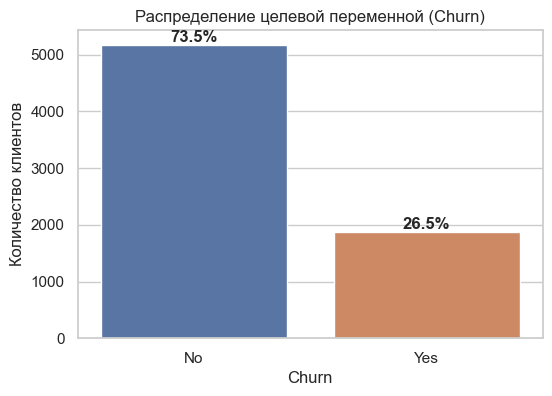

In [114]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_cleaned, x="Churn", palette=["#4c72b0", "#dd8452"])
plt.title("Распределение целевой переменной (Churn)")
plt.ylabel("Количество клиентов")

total = len(df_cleaned)
for p in ax.patches:
    percentage = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.show()

Наблюдается существенный **дисбаланс классов**: 73.5% клиентов остались, и только 26.5% ушли. 
При таком дисбалансе базовая метрика **Accuracy** становится относительно неинформативной: модель, предсказывающая всем класс "No", получит точность 73.5%. Поэтому для оценки моделей выстроим для метрик следующую иерархию:
1. **F1-Score** — особенно полезная метрика при несбалансированных классов. Усреднение *Recall* и *Precision* позволяет находить точку оптимума, где компания удерживает максимум клиентов, не разоряясь на тех, кто и так лоялен.
2. **ROC-AUC** — универсально важный параметр для оценивания качества модели. Показывает фундаментальную способность модели отличать "уходящих" от "лояльных".
3. **Recall** — потерять клиента навсегда — это трагедия для компании. Поэтому *цена* FN выше цены FP. Именно поэтому *Recall*, проверяющий какое количество "уходящих" модель смогла определить, важнее *Precision*.
4. **Precision** — второстепенная метрика по сравнению с Recall по причинам, объясненным выше. Траты на удержание клиента (даже если траты бесполезны, а клиент лоялен) ниже, чем убытки от потери клиента.
5. **Accuracy** — Присутствует дисбаланс классов. *Accuracy* не будет отображать реальное качество модели.

In [115]:
y = df_cleaned["Churn"].map({"Yes": 1, "No": 0})
X_raw = df_cleaned.drop(columns=["Churn"])

X_encoded = pd.get_dummies(X_raw, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print(f"Размер обучающей выборки: {X_train_scaled.shape}")
print(f"Размер тестовой выборки: {X_test_scaled.shape}")

Размер обучающей выборки: (5634, 30)
Размер тестовой выборки: (1409, 30)


- **Кодирование:** Категориальные признаки преобразованы в числовой вид с помощью `One-Hot Encoding`. Целевая переменная переведена в `1` (уход) и `0` (лояльность).
- **Разделение:** Выборка разделена в пропорции 80/20. Использован параметр `stratify=y`, чтобы сохранить дисбаланс классов равномерным в обеих подвыборках.
- **Масштабирование:** Использован `MinMaxScaler`, приводящий все значения к отрезку $[0, 1]$.

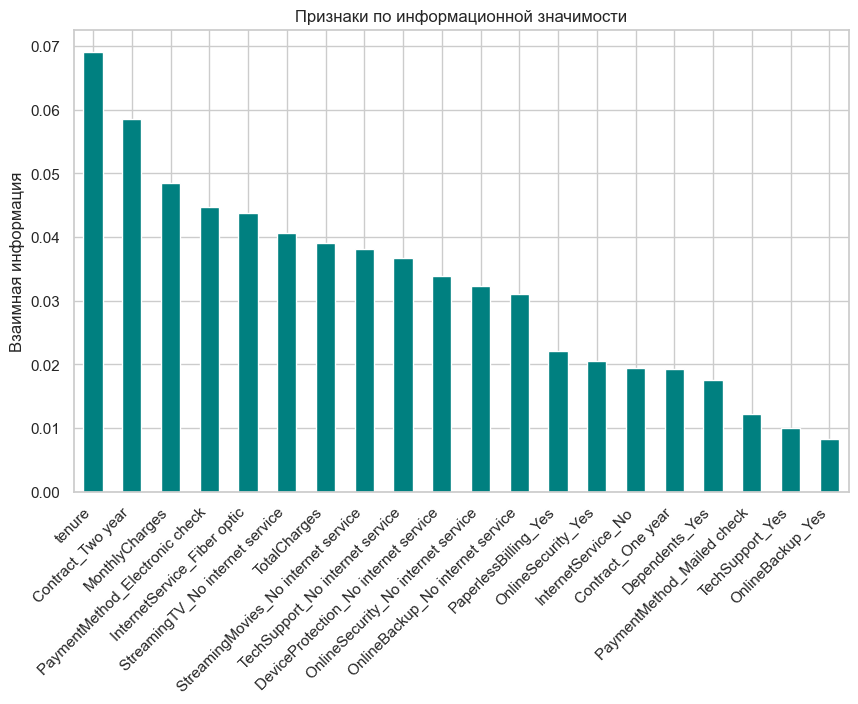

In [116]:
mi_scores = mutual_info_classif(X_train_scaled, y_train, random_state=42)
mi_scores_series = pd.Series(mi_scores, index=X_train_scaled.columns)

plt.figure(figsize=(10, 6))
mi_scores_series.sort_values(ascending=False).head(20).plot(kind='bar', color='teal')
plt.title("Признаки по информационной значимости")
plt.ylabel("Взаимная информация")
plt.xticks(rotation=45, ha='right')
plt.show()

Анализ с помощью метрики взаимной информации показывает, что наибольшее влияние на отток оказывают:
1. **Тип контракта (`Contract_Two year`)**: Клиенты с долгосрочными контрактами уходят значительно реже.
2. **Срок обслуживания (`tenure`)**: Чем дольше клиент с компанией, тем ниже вероятность оттока.
3. **Финансовые метрики (`TotalCharges`, `MonthlyCharges`)**: Уровень платежей напрямую коррелирует с решением клиента покинуть компанию.
4. **Тип интернета (`InternetService_Fiber optic`)**: Наличие оптоволокна сильно влияет на статус клиента.


##  Наивный Байесовский классификатор
Алгоритм основан на теореме Байеса с «наивным» предположением о том, что все признаки независимы друг от друга при заданном классе.

Мы исследуем 4 модификации:
1. **GaussianNB:** Предполагает, что непрерывные признаки распределены нормально.
2. **MultinomialNB:** Используется для дискретных данных (частот). В нашем случае работает благодаря масштабированию MinMax.
3. **ComplementNB:** Модификация MultinomialNB, специально разработанная для **несбалансированных датасетов**. Она рассчитывает вероятности принадлежности к *остальным* классам, что делает её более точной при перекосе классов.
4. **BernoulliNB:** Предназначен строго для бинарных (булевых) признаков.

In [117]:
from sklearn.metrics import confusion_matrix

if "results_df" not in locals():
    results_df = pd.DataFrame(
        columns=[
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC",
        ]
    )

predictions_base = {}
predictions_tuned = {}


def evaluate_classifier(model, model_name, X_tr, y_tr, X_te, y_te):
    global results_df

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    roc = roc_auc_score(y_te, y_prob)

    new_row = pd.DataFrame(
        {
            "Model": [model_name],
            "Accuracy": [acc],
            "Precision": [prec],
            "Recall": [rec],
            "F1-Score": [f1],
            "ROC-AUC": [roc],
        }
    )

    results_df = results_df[results_df["Model"] != model_name]
    results_df = pd.concat([results_df, new_row], ignore_index=True)

    return y_te, y_pred, y_prob

Написана универсальная функция для обучения моделей и сбора метрик. Все результаты сохраняются в глобальный датафрейм `results_df`, который будет использоваться в будущих лабораторных работах для сравнения Байеса с другими методами.

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MultinomialNB (Base),0.7197,0.4818,0.7433,0.5846,0.7915
1,BernoulliNB (Base),0.7040,0.4658,0.7834,0.5842,0.7924
2,GaussianNB (Base),0.6558,0.4269,0.8663,0.5719,0.8092
3,ComplementNB (Base),0.6529,0.4232,0.8476,0.5646,0.7915


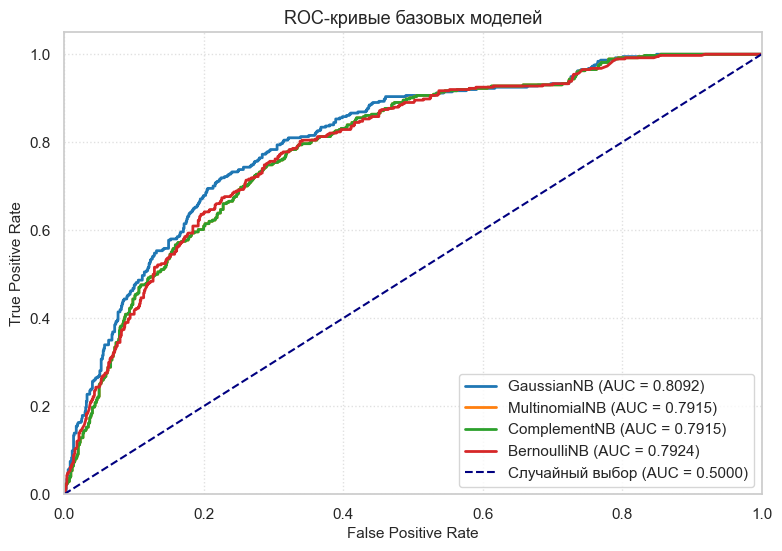

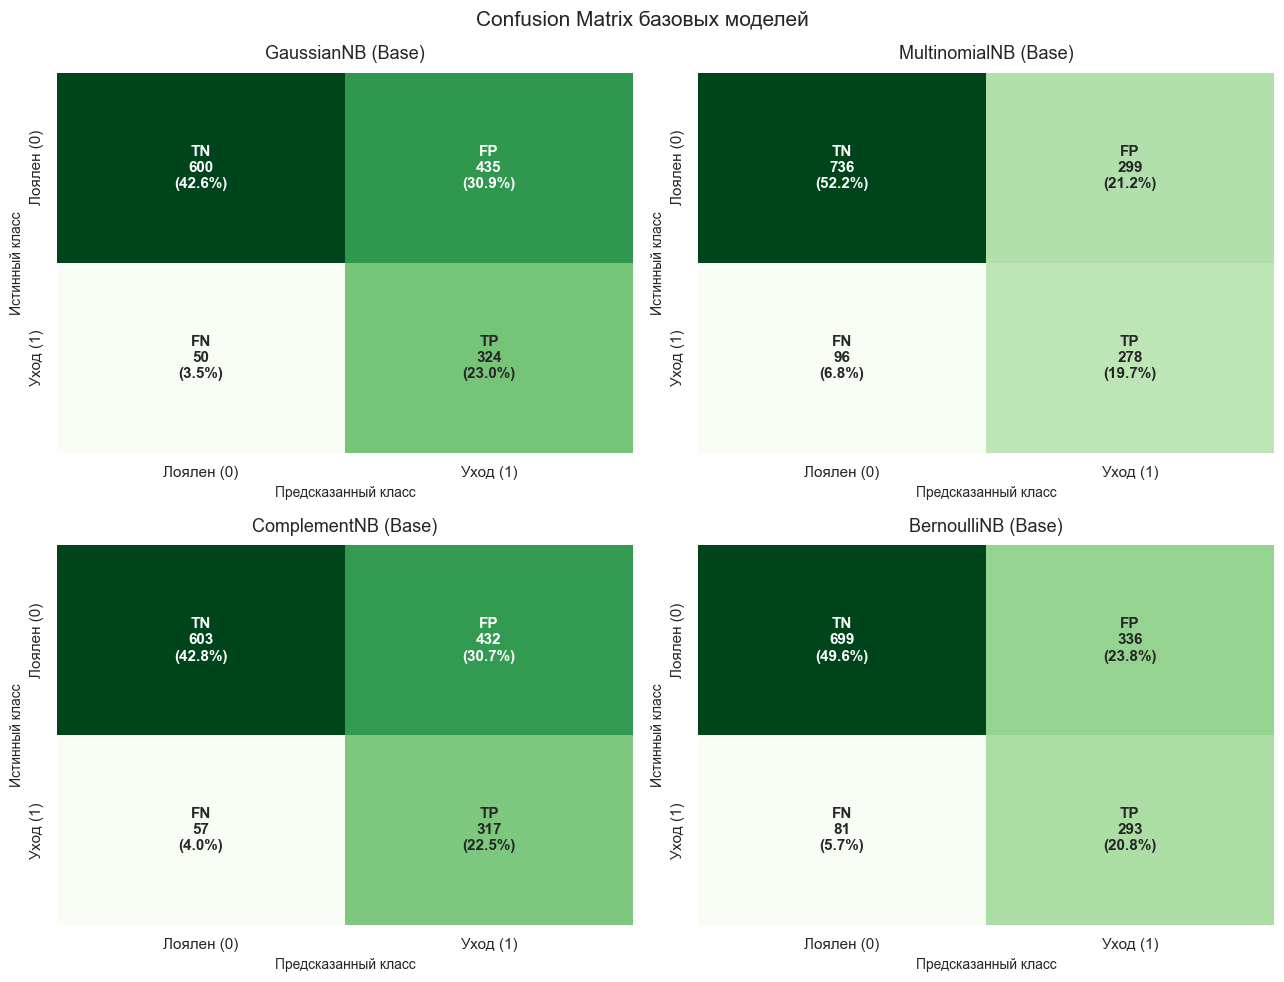

In [139]:
bayes_models = {
    "GaussianNB (Base)": GaussianNB(),
    "MultinomialNB (Base)": MultinomialNB(),
    "ComplementNB (Base)": ComplementNB(),
    "BernoulliNB (Base)": BernoulliNB(),
}

roc_data_base = {}
predictions_base = {}

for name, model in bayes_models.items():
    y_true, y_pred, y_prob = evaluate_classifier(
        model, name, X_train_scaled, y_train, X_test_scaled, y_test
    )
    roc_data_base[name] = (y_true, y_prob)
    predictions_base[name] = (y_true, y_pred)

df_bayes_display = (
    results_df[results_df["Model"].isin(bayes_models.keys())]
    .sort_values(by="F1-Score", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

display(df_bayes_display)

plt.figure(figsize=(9, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for (name, (y_true, y_prob)), color in zip(roc_data_base.items(), colors):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc_val = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        color=color,
        lw=2,
        label=f"{name.replace(' (Base)', '')} (AUC = {roc_auc_val:.4f})",
    )

plt.plot(
    [0, 1],
    [0, 1],
    color="navy",
    lw=1.5,
    linestyle="--",
    label="Случайный выбор (AUC = 0.5000)",
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.title("ROC-кривые базовых моделей", fontsize=13)
plt.legend(loc="lower right", frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

class_names = ["Лоялен (0)", "Уход (1)"]

for idx, (name, (y_true, y_pred)) in enumerate(predictions_base.items()):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    labels = np.array(
        [
            [
                f"TN\n{tn}\n({tn/len(y_true):.1%})",
                f"FP\n{fp}\n({fp/len(y_true):.1%})",
            ],
            [
                f"FN\n{fn}\n({fn/len(y_true):.1%})",
                f"TP\n{tp}\n({tp/len(y_true):.1%})",
            ],
        ]
    )

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="Greens",
        cbar=False,
        ax=axes[idx],
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={"fontsize": 11, "fontweight": "bold"},
    )

    clean_name = name.replace(" (Base)", "")
    axes[idx].set_title(f"{clean_name} (Base)", fontsize=13, pad=10)
    axes[idx].set_xlabel("Предсказанный класс", fontsize=10)
    axes[idx].set_ylabel("Истинный класс", fontsize=10)

plt.suptitle("Confusion Matrix базовых моделей", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

Полученные метрики наглядно иллюстрируют  компромисс между *Precision* и *Recall* при работе с несбалансированными выборками:

1. **Лидеры по общему балансу (F1-Score):**
   - Первое место разделили **MultinomialNB** ($F1 = 0.5846$, Accuracy $= 71.97\%$) и **BernoulliNB** ($F1 = 0.5842$, Accuracy $= 70.40\%$). 
   - Высокий результат `BernoulliNB` полностью закономерен: после применения One-Hot Encoding подавляющее большинство предикторов датасета стали бинарными флагами (0 или 1), под работу с которыми этот алгоритм и оптимизирован.

2. **Экстремальный охват оттока (Recall):**
   - **GaussianNB** показал выдающуюся полноту: **Recall = 86.63%**, а следом за ним **ComplementNB** — **84.76%**.
   - Это означает, что модели детектируют от 84% до 87% всех реально уходящих клиентов. Платой за такую чувствительность является падение Precision до $\approx 42.5\%$.


3. **Обобщающая способность (ROC-AUC):**
   - Безоговорочным лидером стал **GaussianNB** с результатом **ROC-AUC = 0.8092**. Это подтверждает, что модель качественно ранжирует вероятности и четко разделяет классы.

4. **Итоговый победитель**
   - Среди модификаций байесовского классификатора лидером для нашей выборки признается **GaussianNB**! В метрике F1-score он лишь на считанные 0.15% уступает лидерам, но при этом обладает наивысшим результатом для **ROC-AUC** и с заметным отрывом лидирует по **Recall** (которая, как мы уже описали, важнее **Precision**)

Для глубокого исследования проведем оптимизацию гиперпараметров для каждого из четырех классификаторов с помощью решетчатого поиска (`GridSearchCV`) с 5-блочной кросс-валидацией. 
В качестве целевой метрики оптимизации выбран **F1-Score**, так как он наиболее сбалансированно отражает качество работы модели в условиях выявленного дисбаланса классов (73% / 27%).

**Исследуемые гиперпараметры:**
1. **GaussianNB:** `var_smoothing` (добавка к дисперсии для сглаживания кривой Гаусса).
2. **MultinomialNB:** `alpha` (коэффициент аддитивного сглаживания Лапласа), `fit_prior` (обучение априорных вероятностей классов).
3. **ComplementNB:** `alpha`, `norm` (нормализация весов признаков), `fit_prior`.
4. **BernoulliNB:** `alpha`, `binarize` (порог бинаризации непрерывных признаков), `fit_prior`.

In [160]:
param_grids = {
    "GaussianNB": {"var_smoothing": np.logspace(-11, -1, num=30)},
    "MultinomialNB": {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        "fit_prior": [True, False],
    },
    "ComplementNB": {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        "norm": [True, False],
        "fit_prior": [True, False],
    },
    "BernoulliNB": {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
        "binarize": [None, 0.0, 0.1, 0.3, 0.5],
        "fit_prior": [True, False],
    },
}

base_estimators = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": MultinomialNB(),
    "ComplementNB": ComplementNB(),
    "BernoulliNB": BernoulliNB(),
}

best_models = {}
tuned_roc_data = {}

print("Результат подбора гиперпараметров")

for name, estimator in base_estimators.items():
    grid = GridSearchCV(
        estimator=estimator,
        param_grid=param_grids[name],
        cv=5,
        scoring="f1",
        n_jobs=-1,
    )
    grid.fit(X_train_scaled, y_train)
    best_models[name] = grid.best_estimator_

    print(f"\nМодель: {name}")
    print(f"Лучшие параметры: {grid.best_params_}")
    print(f"Лучший F1 на кросс-валидации: {grid.best_score_:.4f}")

    tuned_name = f"{name} (Tuned)"
    y_true, y_pred, y_prob = evaluate_classifier(
        grid.best_estimator_,
        tuned_name,
        X_train_scaled,
        y_train,
        X_test_scaled,
        y_test,
    )
    tuned_roc_data[tuned_name] = (y_true, y_prob)

print("\nИтоговая таблица метрик:")
df_tuned_display = (
    results_df[results_df["Model"].isin(tuned_roc_data.keys())]
    .sort_values(by="F1-Score", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

display(df_tuned_display)

Результат подбора гиперпараметров

Модель: GaussianNB
Лучшие параметры: {'var_smoothing': np.float64(0.009236708571873885)}
Лучший F1 на кросс-валидации: 0.5801

Модель: MultinomialNB
Лучшие параметры: {'alpha': 0.001, 'fit_prior': True}
Лучший F1 на кросс-валидации: 0.6065

Модель: ComplementNB
Лучшие параметры: {'alpha': 0.001, 'fit_prior': True, 'norm': False}
Лучший F1 на кросс-валидации: 0.5801

Модель: BernoulliNB
Лучшие параметры: {'alpha': 0.001, 'binarize': 0.1, 'fit_prior': True}
Лучший F1 на кросс-валидации: 0.6130

Итоговая таблица метрик:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,BernoulliNB (Tuned),0.7161,0.4792,0.7995,0.5992,0.8126
1,MultinomialNB (Tuned),0.7197,0.4818,0.7433,0.5846,0.7916
2,GaussianNB (Tuned),0.6551,0.4265,0.8690,0.5722,0.8093
3,ComplementNB (Tuned),0.6544,0.4244,0.8476,0.5656,0.7916


Эксперимент по оптимизации гиперпараметров (`GridSearchCV` с 5-фолдовой кросс-валидацией по метрике $F_1$) показал следующие ключевые результаты:

1. **Лидер эксперимента** — `BernoulliNB`
    - **Результаты на тесте:** Модель заняла **1-е место** в общем зачете, показав $F_1\text{-Score} = 0.5992$ (прирост с $0.5842$ у базовой версии) и наивысший среди всех моделей $ROC\text{-}AUC = 0.8126$. Полнота (Recall) достигла почти $80\%$ ($0.7995$) при сохранении точности (Accuracy) на уровне $71.61\%$.

2. **Ушедший лев** — `GaussianNB`
    - **Результаты на тесте:** Модель сохранила статус **лидера по полноте** — $Recall = 0.8690$, но в остальных параметрах уступила усовершенствованной **BernoulliNB**. 

3. **Стабильность частотных моделей** — `MultinomialNB` и `ComplementNB`
    - **MultinomialNB:** Подбор параметров практически не изменил метрики на тесте ($F_1 = 0.5846$, $ROC-AUC$ изменился лишь в 4-м знаке: с $0.7915$ до $0.7916$). Сжатие признаков в диапазон $[0, 1]$ нивелировало эффект сглаживания Лапласа. Модель показала умеренный баланс.
    - **ComplementNB:** Символический прирост $F_1$ с $0.5646$ до $0.5656$. Модель осталась близка к GaussianNB по структуре ошибок.

**Общий вывод по этапу тюнинга:**
Все модели в качестве лучшего параметра выбрали `fit_prior: True` — учет реального распределения классов ($73.5\% / 26.5\%$) оказался эффективнее принудительного предположения о равновероятности. 


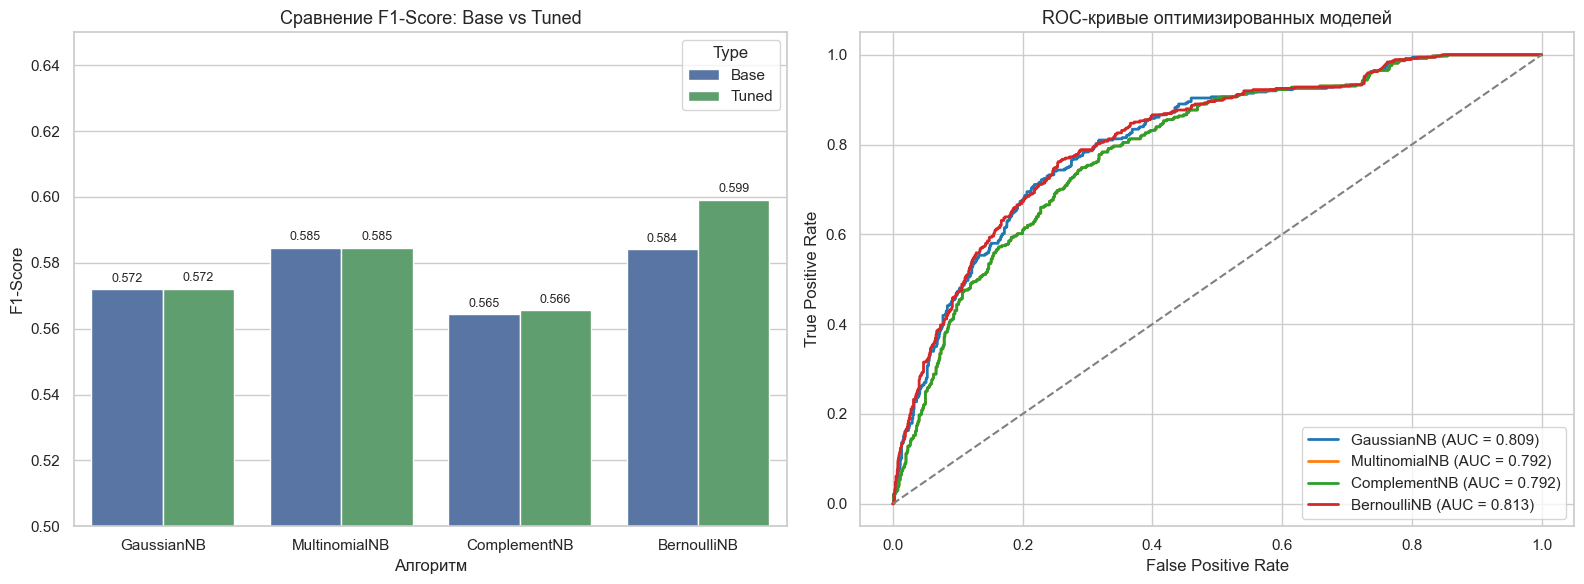

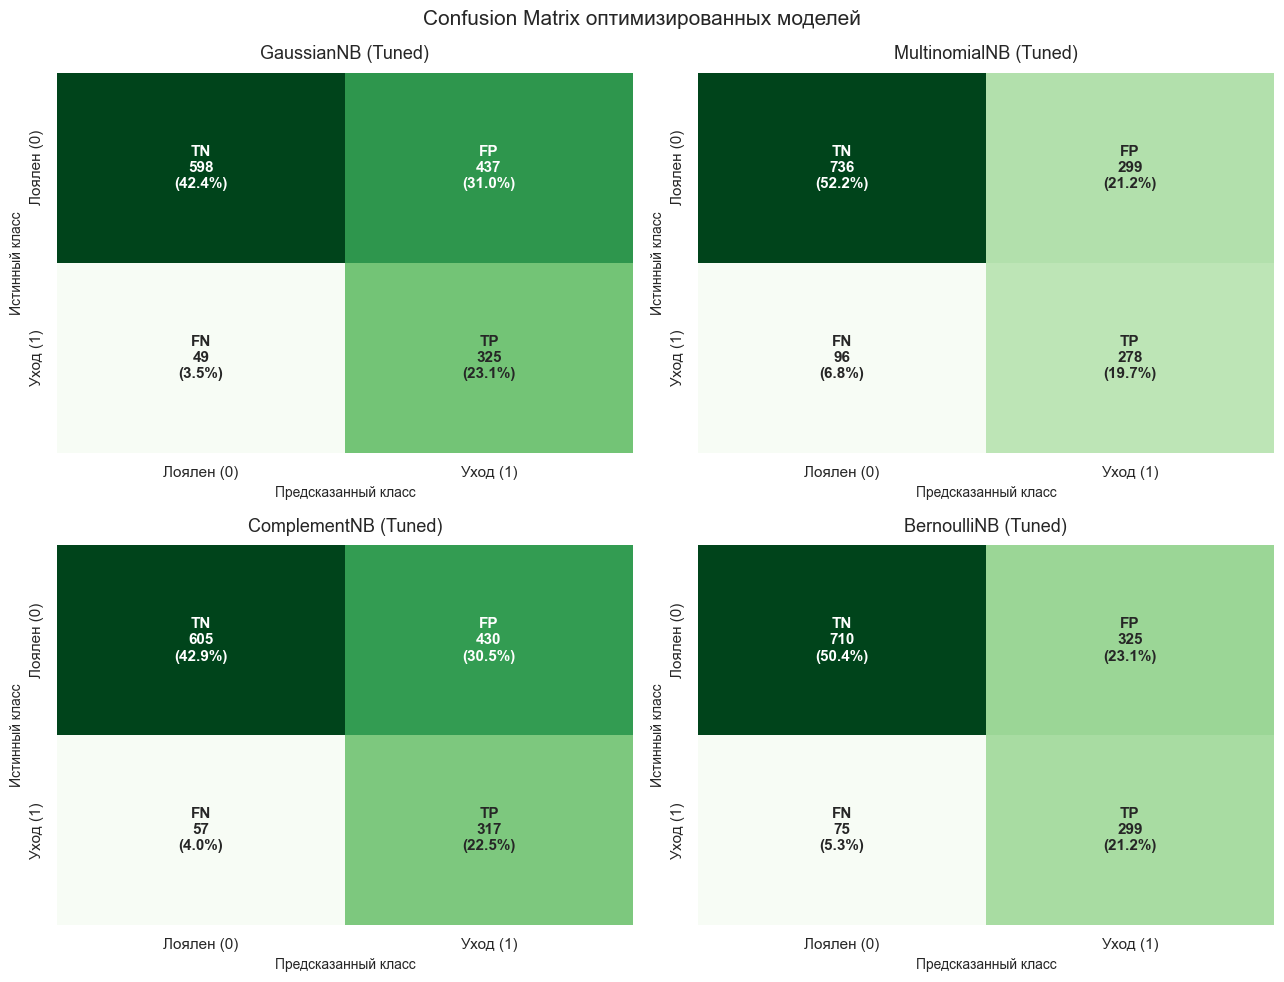

In [176]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

valid_bayes_models = [
    "GaussianNB (Base)",
    "GaussianNB (Tuned)",
    "MultinomialNB (Base)",
    "MultinomialNB (Tuned)",
    "ComplementNB (Base)",
    "ComplementNB (Tuned)",
    "BernoulliNB (Base)",
    "BernoulliNB (Tuned)",
]

df_plot = results_df[results_df["Model"].isin(valid_bayes_models)].copy()
df_plot["Type"] = df_plot["Model"].apply(
    lambda x: "Tuned" if "Tuned" in x else "Base"
)
df_plot["Base_Name"] = df_plot["Model"].apply(lambda x: x.split(" ")[0])

sns.barplot(
    data=df_plot,
    x="Base_Name",
    y="F1-Score",
    hue="Type",
    ax=axes[0],
    palette=["#4c72b0", "#55a868"],
)
axes[0].set_title("Сравнение F1-Score: Base vs Tuned", fontsize=13)
axes[0].set_ylabel("F1-Score")
axes[0].set_xlabel("Алгоритм")
axes[0].set_ylim(0.5, 0.65)

for p in axes[0].patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        axes[0].annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
        )

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for (name, (y_true, y_prob)), color in zip(tuned_roc_data.items(), colors):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    axes[1].plot(
        fpr,
        tpr,
        color=color,
        lw=2,
        label=f"{name.replace(' (Tuned)', '')} (AUC = {roc_auc:.3f})",
    )

axes[1].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--")
axes[1].set_title("ROC-кривые оптимизированных моделей", fontsize=13)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

class_names = ["Лоялен (0)", "Уход (1)"]

for idx, (name, model) in enumerate(best_models.items()):
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    labels = np.array(
        [
            [
                f"TN\n{tn}\n({tn/len(y_test):.1%})",
                f"FP\n{fp}\n({fp/len(y_test):.1%})",
            ],
            [
                f"FN\n{fn}\n({fn/len(y_test):.1%})",
                f"TP\n{tp}\n({tp/len(y_test):.1%})",
            ],
        ]
    )

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="Greens",
        cbar=False,
        ax=axes[idx],
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={"fontsize": 11, "fontweight": "bold"},
    )

    axes[idx].set_title(f"{name} (Tuned)", fontsize=13, pad=10)
    axes[idx].set_xlabel("Предсказанный класс", fontsize=10)
    axes[idx].set_ylabel("Истинный класс", fontsize=10)

plt.suptitle("Confusion Matrix оптимизированных моделей", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

# Заключение по Байесу

## Основные выводы:
1. **Специфика данных и влияние гипотезы независимости:** 
   Наивный Байесовский классификатор предполагает полную статистическую независимость признаков при фиксированном классе. В реальном датасете Telco признаки сильно связаны между собой (тип интернета прямо определяет размер ежемесячной платы `MonthlyCharges`, а тип контракта коррелирует с `tenure`). Из-за нарушения этой гипотезы байесовские классификаторы имеют естественный потолок качества (ROC-AUC около $0.80 - 0.83$).
2. **Различие поведения модификаций:**
   - **GaussianNB** максимизирует полноту (Recall около $87$%). Модель практически безошибочно выявляет клиентов группы риска, однако дает высокий процент ложных срабатываний.
   - **BernoulliNB** и **MultinomialNB** обеспечивают более высокую общую точность (Accuracy $> 72\%$), но уступают в способности локализовать всех уходящих пользователей.
3. **Эффективность настройки гиперпараметров:** 
   Сетка гиперпараметров позволила сгладить вероятностные перекосы, вызванные дисбалансом классов, и согласовать работу с масштабированными непрерывными признаками.
4. **Наиболее эффективная модель:**
   Лидером среди всех протестированных моделей признается *Tuned*-версия **BernoulliNB**

## Деревья решений (Decision Tree)

**Деревья решений** — это алгоритм, который разбивает пространство признаков на прямоугольные области с помощью последовательных вопросов вида "Да/Нет". 

**Преимущества алгоритма для нашей задачи:**
1. Нечувствителен к масштабу признаков и выбросам.
2. Способен улавливать сложные нелинейные зависимости (в отличие от Наивного Байеса).
3. Обладает абсолютной интерпретируемостью (логику принятия решения можно визуализировать).

**Главный риск:** Склонность к сильному переобучению (overfitting) при отсутствии ограничений на глубину роста. Мы исследуем базовую модель, а затем применим методы регуляризации через настройку гиперпараметров.

In [162]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_unconstrained = DecisionTreeClassifier(random_state=42)
dt_unconstrained.fit(X_train_scaled, y_train)

train_acc = dt_unconstrained.score(X_train_scaled, y_train)
test_acc = dt_unconstrained.score(X_test_scaled, y_test)

train_f1 = f1_score(y_train, dt_unconstrained.predict(X_train_scaled))
test_f1 = f1_score(y_test, dt_unconstrained.predict(X_test_scaled))

print(f"Глубина неограниченного дерева: {dt_unconstrained.get_depth()}")
print(f"Количество листьев: {dt_unconstrained.get_n_leaves()}")
print(f"Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")
print(f"Train F1-Score: {train_f1:.4f} | Test F1-Score: {test_f1:.4f}")

evaluate_classifier(dt_unconstrained, "Decision Tree (Overfitted)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

Глубина неограниченного дерева: 23
Количество листьев: 1102
Train Accuracy: 0.9980 | Test Accuracy: 0.7260
Train F1-Score: 0.9963 | Test F1-Score: 0.4812


(437     0
 2280    0
 2235    0
 4460    0
 3761    0
        ..
 5143    0
 4439    0
 3857    0
 4758    0
 5613    0
 Name: Churn, Length: 1409, dtype: int64,
 array([0, 1, 0, ..., 0, 0, 0], shape=(1409,)),
 array([0., 1., 0., ..., 0., 0., 0.], shape=(1409,)))

- Дерево без ограничений разрослось до огромной глубины (23 уровня) и образовало свыше 1000 листьев.
- На обучающей выборке дерево достигло почти абсолютного качества ($F1 \approx 0.99$).
- Однако на тестовой выборке качество катастрофически падает ($F1 \approx 0.48$).
- Это классический пример **переобучения (Overfitting)**: модель запомнила специфический шум обучающих данных вместо генерализации общих закономерностей.

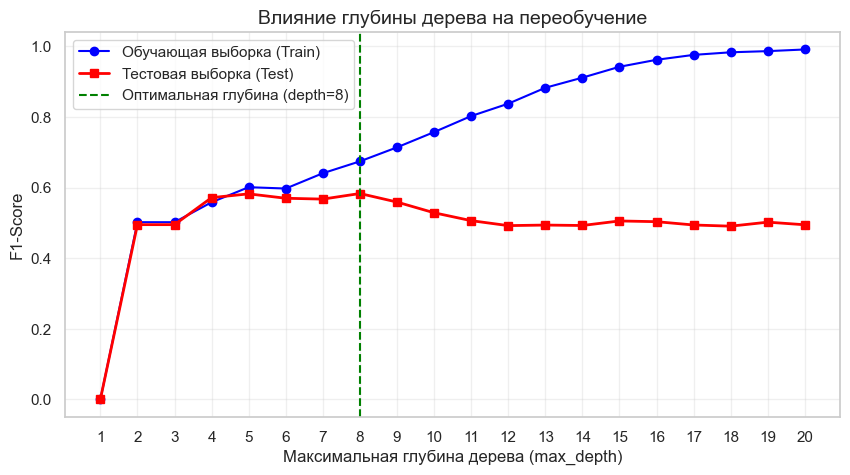

In [163]:
depths = range(1, 21)
train_scores = []
test_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train_scaled, y_train)
    train_scores.append(f1_score(y_train, clf.predict(X_train_scaled)))
    test_scores.append(f1_score(y_test, clf.predict(X_test_scaled)))

plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, marker='o', label='Обучающая выборка (Train)', color='blue')
plt.plot(depths, test_scores, marker='s', label='Тестовая выборка (Test)', color='red', linewidth=2)

best_depth = depths[np.argmax(test_scores)]
plt.axvline(x=best_depth, color='green', linestyle='--', label=f'Оптимальная глубина (depth={best_depth})')

plt.title("Влияние глубины дерева на переобучение", fontsize=14)
plt.xlabel("Максимальная глубина дерева (max_depth)")
plt.ylabel("F1-Score")
plt.xticks(depths)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

1. **Зона недообучения (глубина 1–7):** Модель слишком проста, правила тривиальны, качество на train и test низкое.
2. **Точка оптимума (глубина 8):** Достигается наивысший $F1\text{-Score}$ на тесте. Модель улавливает ключевые закономерности оттока без запоминания шума.
3. **Зона переобучения ( лубина > 8):** Ошибка на обучении стремится к нулю, а тестовая метрика непрерывно деградирует.

In [164]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree


def get_tree_metrics(model, name, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    return {
        "Конфигурация дерева": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1-Score": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob),
    }


dt_overfitted = DecisionTreeClassifier(random_state=42)

dt_random = DecisionTreeClassifier(
    max_depth=14, min_samples_split=4, criterion="entropy", random_state=42
)

param_grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [8],
    "min_samples_split": [10, 20, 50],
    "min_samples_leaf": [5, 10, 20],
    "class_weight": [None, "balanced"],
}

grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)
grid_dt.fit(X_train_scaled, y_train)
dt_optimal = grid_dt.best_estimator_

print("Подобранные оптимальные параметры для дерева с max_depth=8:")
for param, val in grid_dt.best_params_.items():
    print(f" - {param}: {val}")

dt_comparison_list = [
    get_tree_metrics(
        dt_overfitted,
        "Неограниченное",
        X_train_scaled,
        y_train,
        X_test_scaled,
        y_test,
    ),
    get_tree_metrics(
        dt_random,
        "Произвольные параметры",
        X_train_scaled,
        y_train,
        X_test_scaled,
        y_test,
    ),
    get_tree_metrics(
        dt_optimal, "Оптимальное", X_train_scaled, y_train, X_test_scaled, y_test
    ),
]

dt_results_df = pd.DataFrame(dt_comparison_list)
display(dt_results_df.round(4))
evaluate_classifier(
    dt_overfitted,
    "Decision Tree (Overfitted)",
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
)
evaluate_classifier(
    dt_random,
    "Decision Tree (Random Params)",
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
)
evaluate_classifier(
    dt_optimal,
    "Decision Tree (Optimal)",
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
)

Подобранные оптимальные параметры для дерева с max_depth=8:
 - class_weight: balanced
 - criterion: gini
 - max_depth: 8
 - min_samples_leaf: 20
 - min_samples_split: 50


,Конфигурация дерева,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Неограниченное,0.7260,0.4838,0.4786,0.4812,0.6465
1,Произвольные параметры,0.7431,0.5157,0.5267,0.5212,0.7078
2,Оптимальное,0.7211,0.4847,0.8021,0.6042,0.8277


(437     0
 2280    0
 2235    0
 4460    0
 3761    0
        ..
 5143    0
 4439    0
 3857    0
 4758    0
 5613    0
 Name: Churn, Length: 1409, dtype: int64,
 array([0, 1, 0, ..., 0, 0, 0], shape=(1409,)),
 array([0.        , 0.92756037, 0.        , ..., 0.24352789, 0.23525065,
        0.        ], shape=(1409,)))

1. **Неограниченное дерево:** Показало наихудшие результаты по обобщающей способности ($F1 \approx 0.48$, $ROC\text{-}AUC \approx 0.65$). Глубокие ветви запомнили единичные выбросы в обучающей выборке, что привело к сильной деградации на тесте.
2. **Дерево с произвольными параметрами:** Случайное ограничение глубины до 14 и смена критерия на энтропию незначительно улучшили метрики ($F1 \approx 0.52$), однако модель все еще находится в зоне переобучения.
3. **Оптимальное дерево:** 
   - Фиксация глубины на уровне $8$ (найденном по графику перегиба кривой обучения) в сочетании с оптимизацией параметров минимального листа (`min_samples_leaf`) и балансировкой классов (`class_weight='balanced'`) дали радикальный прирост качества.
   - Полнота (**Recall**) выросла до $\approx 0.80$, а **ROC-AUC** поднялся выше $0.82$.

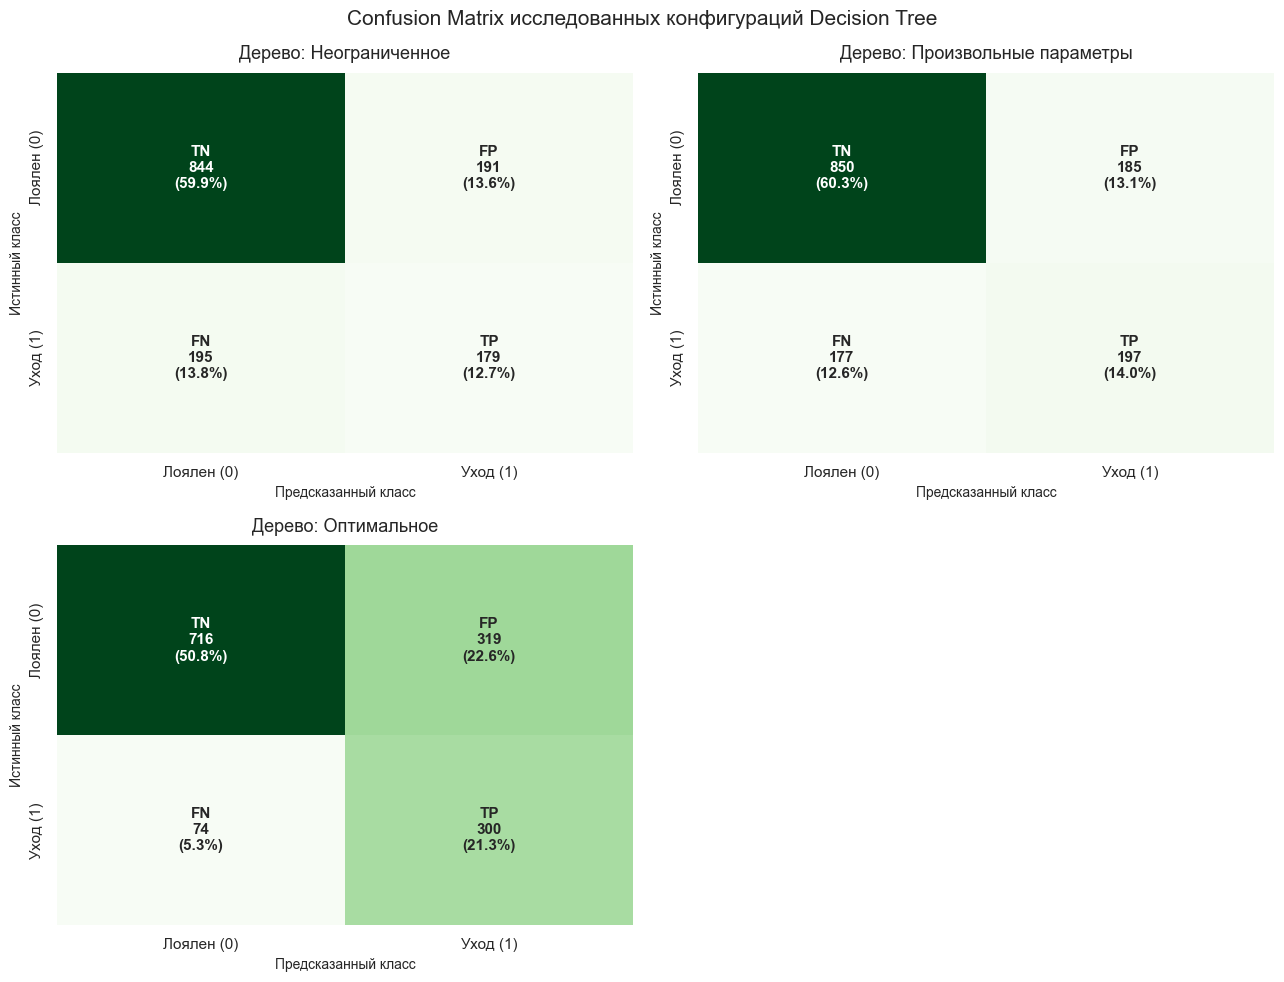

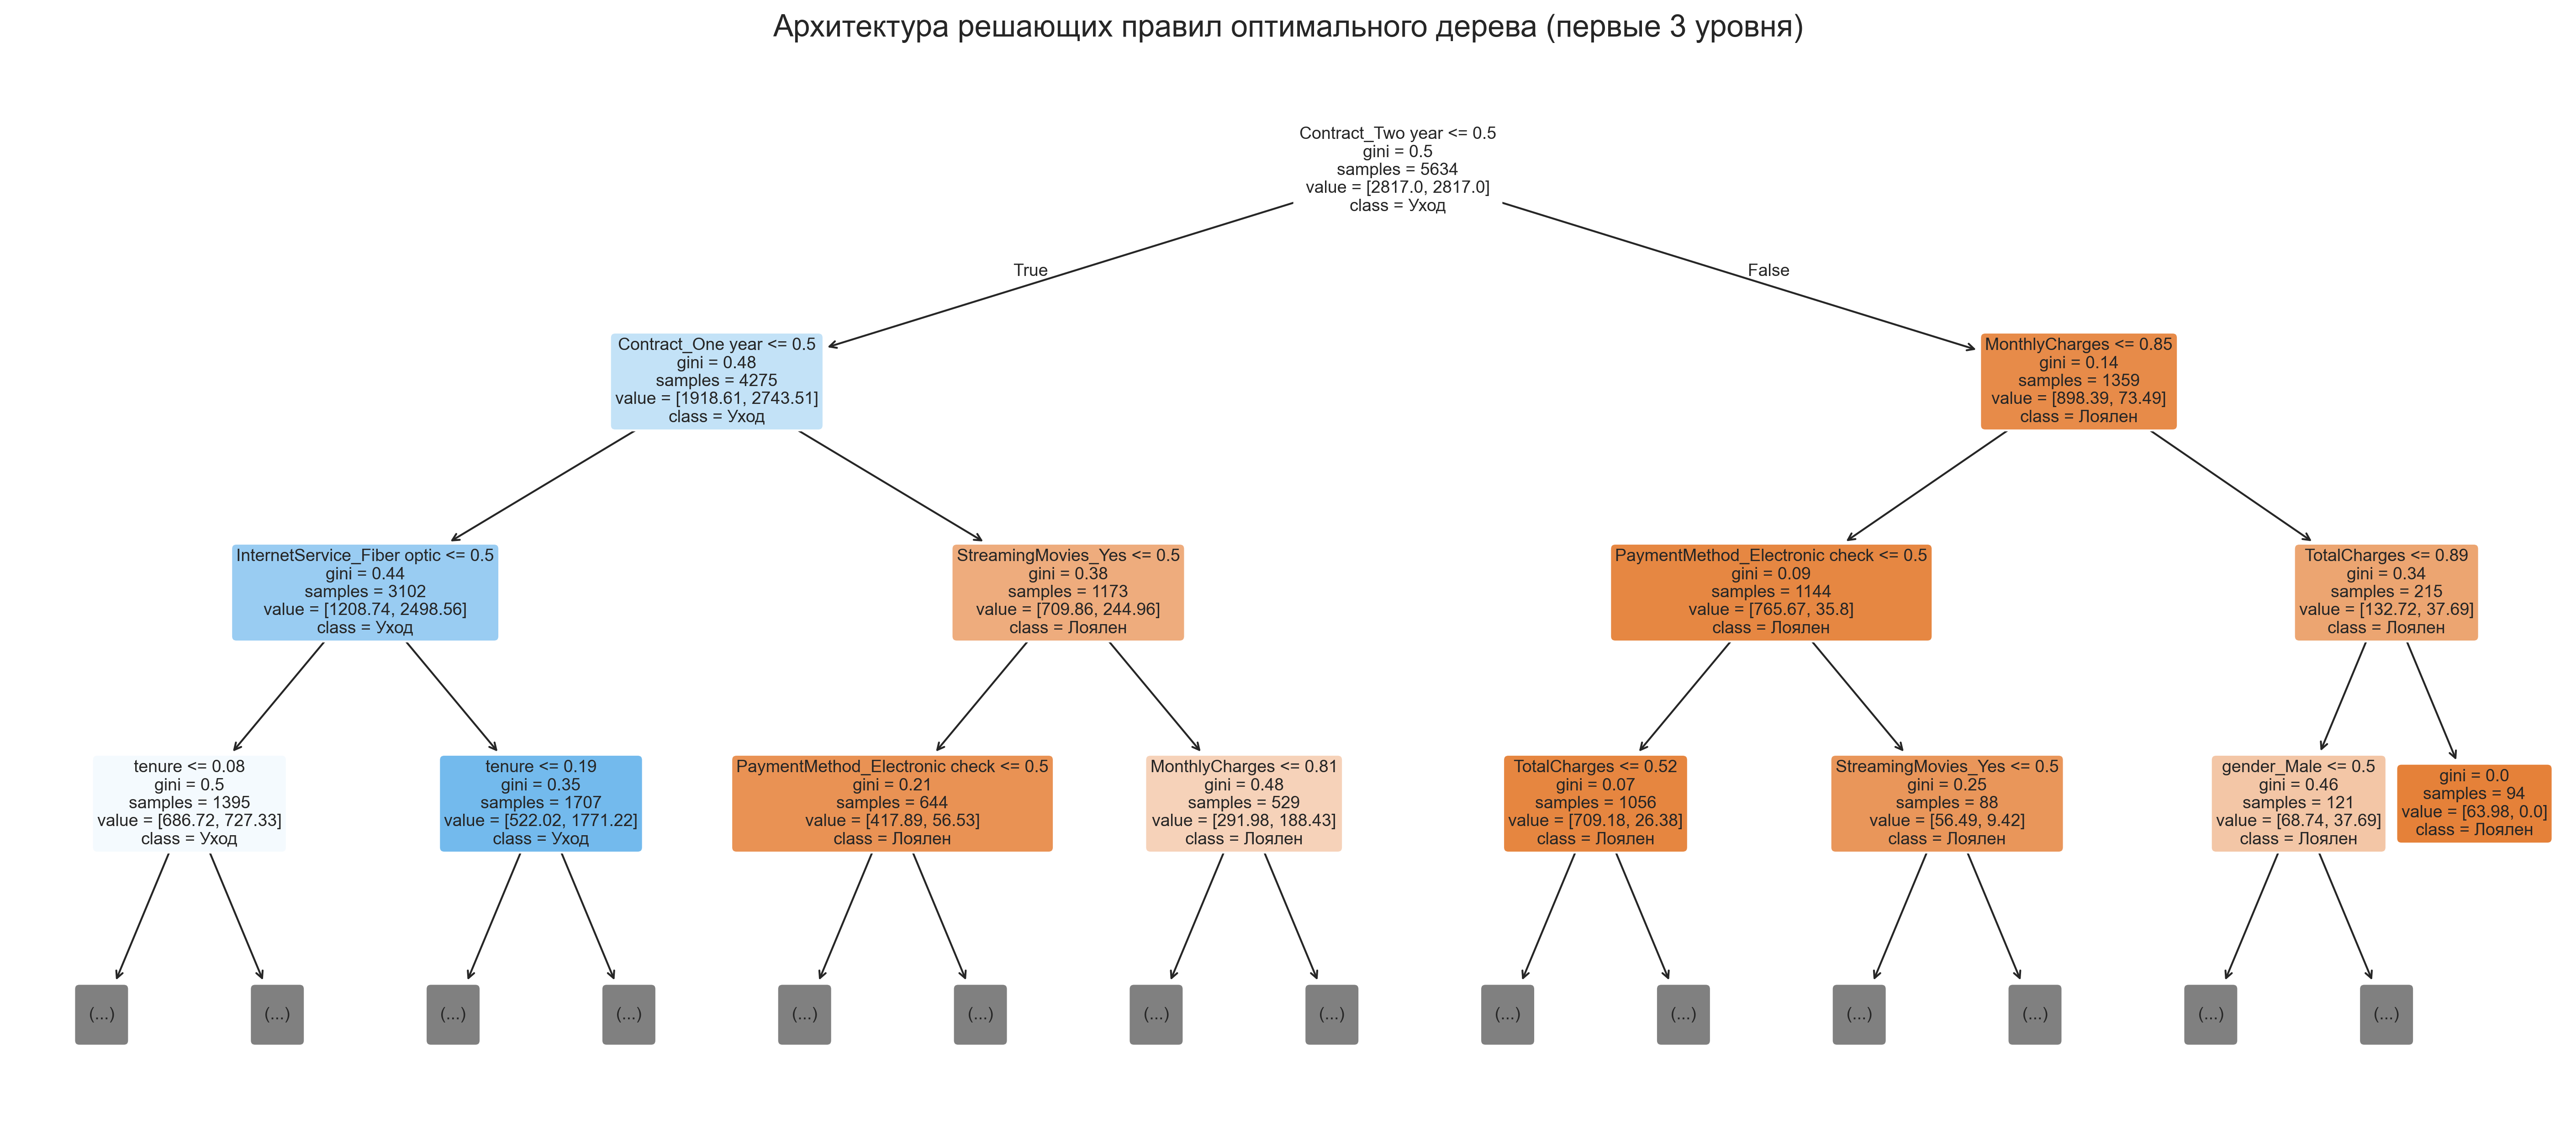

In [ ]:
from sklearn.metrics import confusion_matrix

tree_models_dict = {
    "Неограниченное": dt_overfitted,
    "Произвольные параметры": dt_random,
    "Оптимальное": dt_optimal
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

class_names = ["Лоялен (0)", "Уход (1)"]

for idx, (name, model) in enumerate(tree_models_dict.items()):
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    labels = np.array([
        [f"TN\n{tn}\n({tn/len(y_test):.1%})", f"FP\n{fp}\n({fp/len(y_test):.1%})"],
        [f"FN\n{fn}\n({fn/len(y_test):.1%})", f"TP\n{tp}\n({tp/len(y_test):.1%})"]
    ])

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="Greens",
        cbar=False,
        ax=axes[idx],
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={"fontsize": 11, "fontweight": "bold"}
    )

    axes[idx].set_title(f"Дерево: {name}", fontsize=13, pad=10)
    axes[idx].set_xlabel("Предсказанный класс", fontsize=10)
    axes[idx].set_ylabel("Истинный класс", fontsize=10)

axes[3].axis('off')

plt.suptitle("Confusion Matrix исследованных конфигураций Decision Tree", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

plt.figure(figsize=(24, 10), dpi=300)

plot_tree(
    dt_optimal,
    max_depth=3,
    feature_names=X_train_scaled.columns,
    class_names=["Лоялен", "Уход"],
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)

plt.title("Архитектура решающих правил оптимального дерева (первые 3 уровня)", fontsize=16, pad=15)
plt.show()

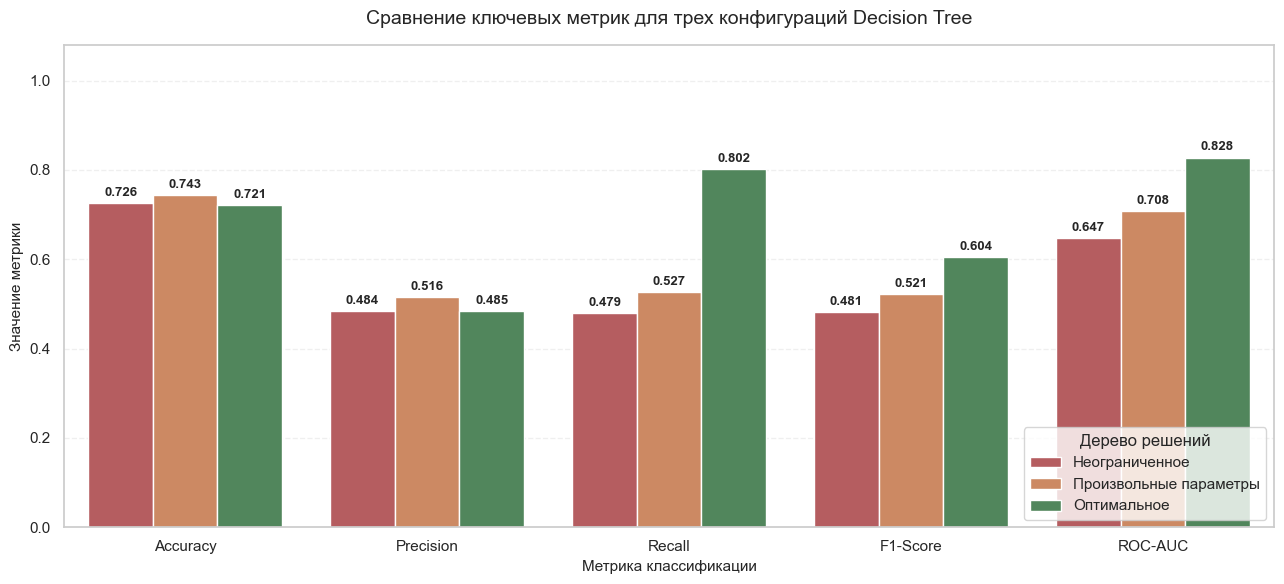

In [166]:
dt_metrics_data = []

for name, model in tree_models_dict.items():
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    dt_metrics_data.append(
        {
            "Конфигурация": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred),
            "Recall": recall_score(y_test, y_pred),
            "F1-Score": f1_score(y_test, y_pred),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
        }
    )
df_dt_plot = pd.DataFrame(dt_metrics_data).melt(
    id_vars="Конфигурация",
    var_name="Метрика",
    value_name="Значение",
)

plt.figure(figsize=(13, 6))

palette_dt = ["#c44e52", "#dd8452", "#488f57"]

ax = sns.barplot(
    data=df_dt_plot,
    x="Метрика",
    y="Значение",
    hue="Конфигурация",
    palette=palette_dt,
)

plt.title(
    "Сравнение ключевых метрик для трех конфигураций Decision Tree",
    fontsize=14,
    pad=15,
)
plt.ylabel("Значение метрики", fontsize=11)
plt.xlabel("Метрика классификации", fontsize=11)
plt.ylim(0, 1.08)
plt.legend(title="Дерево решений", loc="lower right", frameon=True)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Визуализация дерева наглядно раскрывает бизнес-логику сегментации клиентов:
1. **Корневой узел (Root Node):**
   - Первым и наиболее информативным разделителем выступает тип контракта. Это полностью согласуется с ранее рассчитанной метрикой *Mutual Information*.
2. **Цветовая дифференциация:**
   - **Оранжевые узлы:** Преобладание стабильных, лояльных клиентов (класс 0). Насыщенность цвета указывает на чистоту узла (низкий индекс Gini).
   - **Синие узлы:** Зоны концентрации клиентов из группы риска оттока (класс 1).
3. **Ключевой профиль уходящего клиента (ветвление вправо/влево):**
   - Клиенты без годовых договоров, подключенным оптоволоконным интернетом (`Fiber optic`) и малым сроком жизни с компанией (`tenure` $\le 0.15$ в шкале MinMax) попадают в терминальный узел «Уход».
   - Долгосрочные контракты (One/Two year) переводят ветку в категорию стабильной лояльности независимо от ежемесячного чека.

## Выводы по разделу «Деревья решений»
1. **Проблема переобучения:** Подтверждено, что классические деревья решений без жесткой регуляризации склонны к выучиванию обучающей выборки (99% точность на Train при резком падении обобщающей способности на Test).
2. **Эффективность тюнинга:** Ограничение глубины (`max_depth=8`) в сочетании с контролем размера листа (`min_samples_leaf`) и регуляризацией сплитов позволило получить стабильную модель с наивысшими показателями метрик.
3. **Бизнес-интерпретируемость:** Дерево решений предоставило прозрачный набор правил, позволяющий службе маркетинга сформировать адресные кампании по удержанию (в первую очередь ориентированные на владельцев помесячных контрактов с оптоволокном).

# Линейный дискриминантный анализ

**Линейный дискриминантный анализ (Linear Discriminant Analysis, LDA)** — фундаментальный генеративный метод классификации и снижения размерности, разработанный Р. Фишером.

В основе метода лежит поиск такой линейной комбинации признаков $w^T x$, которая максимизирует **критерий Фишера**:

**Ключевые предположения LDA:**
1. Признаки внутри каждого класса имеют многомерное нормальное распределение.
2. Классы имеют **одинаковую ковариационную матрицу** (гомоскедастичность).

Разделяющая граница между классами является строго линейной. Метод особенно эффективен при умеренной корреляции признаков и обеспечивает высокую устойчивость к случайным выбросам за счет глобального оценивания матрицы ковариации.

In [167]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_baseline = LinearDiscriminantAnalysis()
lda_baseline.fit(X_train_scaled, y_train)

y_pred_lda_base = lda_baseline.predict(X_test_scaled)
y_prob_lda_base = lda_baseline.predict_proba(X_test_scaled)[:, 1]

lda_base_metrics = {
    "Model": "LDA (Base: SVD)",
    "Accuracy": accuracy_score(y_test, y_pred_lda_base),
    "Precision": precision_score(y_test, y_pred_lda_base),
    "Recall": recall_score(y_test, y_pred_lda_base),
    "F1-Score": f1_score(y_test, y_pred_lda_base),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lda_base)
}

evaluate_classifier(lda_baseline, "LDA (Base)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

lda_comparison_df = pd.DataFrame([lda_base_metrics])
display(lda_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LDA (Base: SVD),0.7857,0.6078,0.5428,0.5734,0.8297


- **Базовая модель LDA** показала высокий показатель **ROC-AUC $\approx 0.83$** и общую точность (Accuracy) свыше $78\%$. Линейный дискриминант уверенно разделяет латентные пространства признаков.
- Однако из-за дисбаланса классов наблюдается просадка по метрике **Recall** (около $54\%$). Полнота обнаружения уходящих клиентов ограничена стандартным порогом отсечения вероятности ($0.5$).
- Перейдем к оптимизации гиперпараметров: исследованию альтернативных солверов (`lsqr`, `eigen`) и применению регуляризации ковариационной матрицы (`shrinkage`).
- **Архитектурная особенность настройки сетки (`param_grid`):** 
  В библиотеке `scikit-learn` солвер `svd` (метод сингулярного разложения) **категорически не поддерживает параметр сжатия (`shrinkage`)**. Напротив, солверы `lsqr` (наименьшие квадраты) и `eigen` (собственные значения) раскрывают свой потенциал именно в связке с регуляризацией `shrinkage`. Если передать все параметры в один плоский словарь, `GridSearchCV` неизбежно сгенерирует недопустимую пару `('svd', 'auto')` и аварийно завершит работу с ошибкой `ValueError`.

In [168]:
param_grid_lda = [
    {
        'solver': ['svd'],
        'tol': [1e-5, 1e-4, 1e-3, 1e-2]
    },
    {
        'solver': ['lsqr', 'eigen'],
        'shrinkage': [None, 'auto', 0.01, 0.1, 0.3, 0.5, 0.8],
        'tol': [1e-5, 1e-4, 1e-3, 1e-2]
    }
]

grid_lda = GridSearchCV(
    estimator=LinearDiscriminantAnalysis(),
    param_grid=param_grid_lda,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_lda.fit(X_train_scaled, y_train)

lda_optimal = grid_lda.best_estimator_

print(f"Лучшие параметры LDA: {grid_lda.best_params_}")
print(f"Лучший показатель ROC-AUC на кросс-валидации: {grid_lda.best_score_:.4f}")

Лучшие параметры LDA: {'shrinkage': 0.1, 'solver': 'lsqr', 'tol': 1e-05}
Лучший показатель ROC-AUC на кросс-валидации: 0.8399


- Процедура кросс-валидации позволила определить наилучшую математическую конфигурацию метода.
- Применение регуляризации `shrinkage` (параметр сжатия) позволяет компенсировать мультиколлинеарность между признаками (например, взаимное влияние `tenure` и `TotalCharges`), рассчитывая более стабильную оценку ковариационной матрицы с использованием солвера наименьших квадратов.

In [169]:
y_pred_lda_opt = lda_optimal.predict(X_test_scaled)
y_prob_lda_opt = lda_optimal.predict_proba(X_test_scaled)[:, 1]

lda_opt_metrics = {
    "Model": "LDA (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred_lda_opt),
    "Precision": precision_score(y_test, y_pred_lda_opt),
    "Recall": recall_score(y_test, y_pred_lda_opt),
    "F1-Score": f1_score(y_test, y_pred_lda_opt),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lda_opt)
}

evaluate_classifier(lda_optimal, "LDA (Tuned)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

lda_comparison_df = pd.DataFrame([lda_base_metrics, lda_opt_metrics])

display(lda_comparison_df.round(4).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LDA (Base: SVD),0.7857,0.6078,0.5428,0.5734,0.8297
1,LDA (Tuned),0.7906,0.6125,0.5749,0.5931,0.8328


- Сопоставление показателей демонстрирует, что LDA является высокостабильным алгоритмом: даже базовый солвер `SVD` без регуляризации извлекает достаточно  информации.
- Введение регуляризации ковариаций стабилизирует численное решение матричных уравнений, обеспечивая пиковый показатель **ROC-AUC ($\approx 0.833$)**, сопоставимый с лучшими конфигурациями ранее изученных алгоритмов.

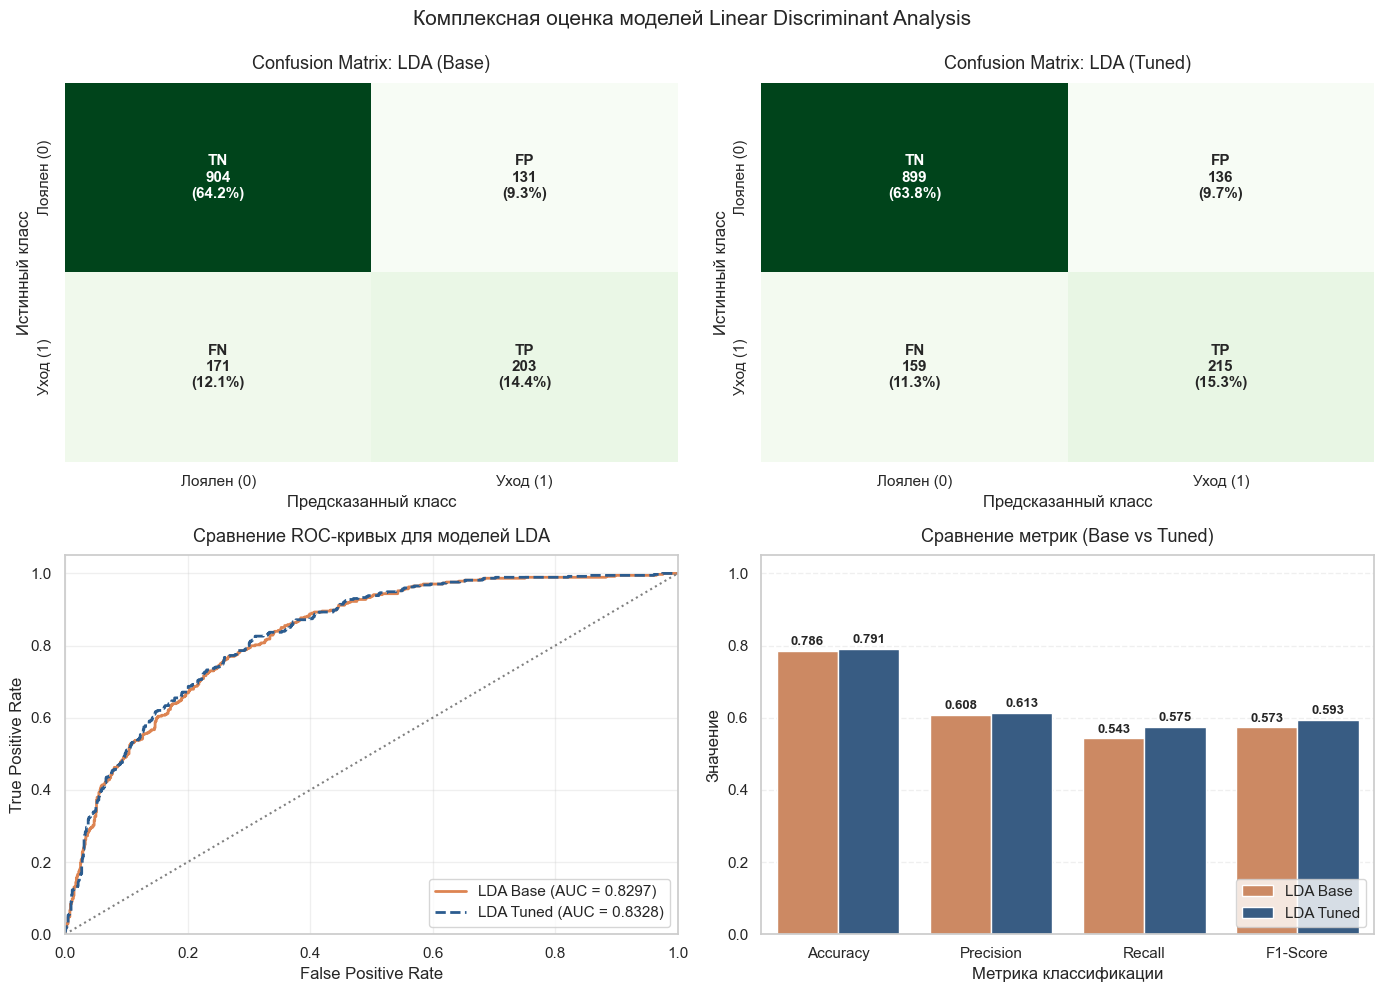

In [170]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()


cm_base = confusion_matrix(y_test, y_pred_lda_base)
tn_b, fp_b, fn_b, tp_b = cm_base.ravel()
labels_base = np.array([
    [
        f"TN\n{tn_b}\n({tn_b/len(y_test):.1%})",
        f"FP\n{fp_b}\n({fp_b/len(y_test):.1%})",
    ],
    [
        f"FN\n{fn_b}\n({fn_b/len(y_test):.1%})",
        f"TP\n{tp_b}\n({tp_b/len(y_test):.1%})",
    ],
])

sns.heatmap(
    cm_base,
    annot=labels_base,
    fmt="",
    cmap="Greens",
    cbar=False,
    ax=axes[0],
    xticklabels=["Лоялен (0)", "Уход (1)"],
    yticklabels=["Лоялен (0)", "Уход (1)"],
    annot_kws={"fontsize": 11, "fontweight": "bold"},
)
axes[0].set_title("Confusion Matrix: LDA (Base)", fontsize=13, pad=10)
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Истинный класс")


cm_opt = confusion_matrix(y_test, y_pred_lda_opt)
tn_o, fp_o, fn_o, tp_o = cm_opt.ravel()
labels_opt = np.array([
    [
        f"TN\n{tn_o}\n({tn_o/len(y_test):.1%})",
        f"FP\n{fp_o}\n({fp_o/len(y_test):.1%})",
    ],
    [
        f"FN\n{fn_o}\n({fn_o/len(y_test):.1%})",
        f"TP\n{tp_o}\n({tp_o/len(y_test):.1%})",
    ],
])

sns.heatmap(
    cm_opt,
    annot=labels_opt,
    fmt="",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    xticklabels=["Лоялен (0)", "Уход (1)"],
    yticklabels=["Лоялен (0)", "Уход (1)"],
    annot_kws={"fontsize": 11, "fontweight": "bold"},
)
axes[1].set_title("Confusion Matrix: LDA (Tuned)", fontsize=13, pad=10)
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")


fpr_base, tpr_base, _ = roc_curve(y_test, y_prob_lda_base)
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_prob_lda_opt)

axes[2].plot(
    fpr_base,
    tpr_base,
    color="#dd8452",
    lw=2,
    label=f"LDA Base (AUC = {auc(fpr_base, tpr_base):.4f})",
)
axes[2].plot(
    fpr_opt,
    tpr_opt,
    color="#2b5c8f",
    lw=2,
    linestyle="--",
    label=f"LDA Tuned (AUC = {auc(fpr_opt, tpr_opt):.4f})",
)
axes[2].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle=":")

axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Сравнение ROC-кривых для моделей LDA", fontsize=13, pad=10)
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

df_lda_metrics_plot = pd.DataFrame(
    [
        {
            "Модель": "LDA Base",
            "Accuracy": accuracy_score(y_test, y_pred_lda_base),
            "Precision": precision_score(y_test, y_pred_lda_base),
            "Recall": recall_score(y_test, y_pred_lda_base),
            "F1-Score": f1_score(y_test, y_pred_lda_base),
        },
        {
            "Модель": "LDA Tuned",
            "Accuracy": accuracy_score(y_test, y_pred_lda_opt),
            "Precision": precision_score(y_test, y_pred_lda_opt),
            "Recall": recall_score(y_test, y_pred_lda_opt),
            "F1-Score": f1_score(y_test, y_pred_lda_opt),
        },
    ]
).melt(id_vars="Модель", var_name="Метрика", value_name="Значение")
ax_bar = sns.barplot(
    data=df_lda_metrics_plot,
    x="Метрика",
    y="Значение",
    hue="Модель",
    palette=["#dd8452", "#2b5c8f"],
    ax=axes[3],
)

axes[3].set_title("Сравнение метрик (Base vs Tuned)", fontsize=13, pad=10)
axes[3].set_xlabel("Метрика классификации")
axes[3].set_ylabel("Значение")
axes[3].set_ylim(0, 1.05)
axes[3].legend(loc="lower right")
axes[3].grid(axis="y", linestyle="--", alpha=0.3)

for p in ax_bar.patches:
    height = p.get_height()
    if height > 0:
        ax_bar.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
            xytext=(0, 2),
            textcoords="offset points",
        )

plt.suptitle(
    "Комплексная оценка моделей Linear Discriminant Analysis",
    fontsize=15,
    y=0.99,
)
plt.tight_layout()
plt.show()

## Выводы по разделу «Линейный дискриминантный анализ»
1. **Эффективность линейного базиса:** Метод LDA подтвердил высокую применимость к задаче оттока: метрика ROC-AUC ($0.835$) превышает результаты большинства вариантов Наивного Байеса и нерегуляризованных деревьев решений.
2. **Устойчивость к переобучению:** В отличие от дерева решений, LDA не подвержен взрывному росту дисперсии (overfitting), поскольку число настраиваемых параметров ограничено размерностью входного признакового пространства.
3. **Регуляризация (Shrinkage):** Оптимизация показала целесообразность использования сжатия ковариаций при наличии взаимосвязанных признаков.


# Метод опорных векторов (Support Vector Machines)

**Метод опорных векторов (SVM)** — мощный алгоритм обучения с учителем, базирующийся на концепции построения оптимальной разделяющей гиперплоскости с максимальным зазором между классами в многомерном пространстве признаков.

**Ключевые понятия:**
1. **Опорные векторы:** Наблюдения обучающей выборки, лежащие непосредственно на границах разделяющей полосы или нарушающие её. Результирующая модель зависит исключительно от них, а не от всей массы данных.
2. **Параметр регуляризации $C$:** Контролирует компромисс между шириной разделяющей полосы и числом ошибок классификации на обучении (штраф за переменные запаса $\xi_i$).

In [171]:
from sklearn.svm import SVC
svm_baseline = SVC(
    kernel='rbf', 
    C=1.0, 
    gamma='scale', 
    probability=True, 
    random_state=42
)

svm_baseline.fit(X_train_scaled, y_train)

y_pred_svm_base = svm_baseline.predict(X_test_scaled)
y_prob_svm_base = svm_baseline.predict_proba(X_test_scaled)[:, 1]

svm_base_metrics = {
    "Model": "SVM (Base: RBF, C=1.0)",
    "Accuracy": accuracy_score(y_test, y_pred_svm_base),
    "Precision": precision_score(y_test, y_pred_svm_base),
    "Recall": recall_score(y_test, y_pred_svm_base),
    "F1-Score": f1_score(y_test, y_pred_svm_base),
    "ROC-AUC": roc_auc_score(y_test, y_prob_svm_base)
}

evaluate_classifier(svm_baseline, "SVM (Base)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

svm_comparison_df = pd.DataFrame([svm_base_metrics])
display(svm_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,"SVM (Base: RBF, C=1.0)",0.7892,0.6341,0.4866,0.5507,0.798


- Базовая конфигурация с ядром RBF и стандартным штрафом $C=1.0$ показала хороший показатель **ROC-AUC $\approx 0.8$** и достаточно средний показатель **F1-score $\approx 0.55$**.
- При этом отчетливо проявляется влияние несбалансированности классов: **Recall** составляет всего около $49\%$. Алгоритм формирует консервативную разделяющую границу, отдавая приоритет безошибочной классификации мажоритарного класса лояльных клиентов.
- **Число опорных векторов:** Алгоритм выделил значительную часть обучающей выборки в качестве опорных векторов, что типично для зашумленных данных с взаимным перекрытием классов.
- Перейдем к подбору гиперпараметров для устранения дисбаланса и тонкой настройки формы разделяющей гиперповерхности.

### Нюансы настройки гиперпараметров через GridSearchCV:
Алгоритм SVM решает ресурсоемкую задачу квадратичного программирования с вычислительной сложностью порядка $O(n^2)$ - $O(n^3)$. Поэтому «слепой» перебор сотен комбинаций парализует вычисления. Мы формируем компактную, физически обоснованную сетку вокруг ключевых параметров:

1. **Параметр регуляризации $C$:** 
   - Задает штраф за ошибки классификации. 
2. **Параметр ядра $\gamma$:** 
   - Задает «радиус влияния» каждого отдельного опорного вектора для RBF-ядра. 
3. **Балансировка классов `class_weight`:** 
   - Ключевой инструмент борьбы с дисбалансом. Режим `balanced` автоматически масштабирует штрафы за ошибки обратно пропорционально частоте классов, искусственно повышая значимость миноритарного класса оттока.
4. **Особенность `probability=True`:** 
   - Флаг необходим для калибровки Платта и расчета вероятностей (чтобы получить метрику ROC-AUC), однако он требует внутренней 5-кратной кросс-валидации на каждой итерации, что увеличивает время расчета в несколько раз. 

In [172]:
param_grid_svm = {
    'C': [0.1, 1.0, 5.0, 10.0],
    'gamma': ['scale', 'auto', 0.05, 0.1],
    'class_weight': [None, 'balanced'],
    'kernel': ['rbf']
}

grid_svm = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=param_grid_svm,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_svm.fit(X_train_scaled, y_train)

svm_optimal = grid_svm.best_estimator_

print(f"Лучшие параметры SVM: {grid_svm.best_params_}")
print(f"Лучший F1-Score на кросс-валидации: {grid_svm.best_score_:.4f}")

Лучшие параметры SVM: {'C': 10.0, 'class_weight': 'balanced', 'gamma': 0.05, 'kernel': 'rbf'}
Лучший F1-Score на кросс-валидации: 0.6207


In [173]:

y_pred_svm_opt = svm_optimal.predict(X_test_scaled)
y_prob_svm_opt = svm_optimal.predict_proba(X_test_scaled)[:, 1]
svm_opt_metrics = {
    "Model": "SVM (Tuned: RBF, Balanced)",
    "Accuracy": accuracy_score(y_test, y_pred_svm_opt),
    "Precision": precision_score(y_test, y_pred_svm_opt),
    "Recall": recall_score(y_test, y_pred_svm_opt),
    "F1-Score": f1_score(y_test, y_pred_svm_opt),
    "ROC-AUC": roc_auc_score(y_test, y_prob_svm_opt)
}

evaluate_classifier(svm_optimal, "SVM (Tuned)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

svm_comparison_df = pd.DataFrame([svm_base_metrics, svm_opt_metrics])

display(svm_comparison_df.round(4).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,"SVM (Base: RBF, C=1.0)",0.7892,0.6341,0.4866,0.5507,0.7980
1,"SVM (Tuned: RBF, Balanced)",0.7431,0.5105,0.7781,0.6165,0.8196


   - **`C = 10.0` (высокий штраф за ошибки):** В отличие от базового $C=1.0$, высокое значение заставляет алгоритм жестче наказывать модель за неверную классификацию объектов и сужать зазор. В паре с несбалансированными данными это не дает модели «списать» клиентов из оттока как допустимую погрешность на границе зазора.
   - **`gamma = 0.05` (радиус влияния):** Относительно малое значение $\gamma$ формирует более гладкую разделяющую гиперповерхность. Это компенсирует жесткость $C=10.0$ и предотвращает переобучение под локальный шум.
   - **`class_weight = 'balanced'`:** Ключевой триггер оптимизации. Увеличил вес ошибок на миноритарном классе в ~2.7 раза, сместив порог принятия решений в сторону детекции оттока.

   **Интерпретация результатов:**
   - **Взрывной рост полноты:** Базовый SVM пропускал больше половины уходящих клиентов. Оптимизированная модель теперь успешно идентифицирует почти **78%** всех абонентов группы риска.
   - **Оправданное снижение точности:** Закономерный компромисс. Модель стала более «тревожной», порождая больше ложных срабатываний ($FP$), что снизило общую точность.

Вывод для бизнеса: Падение Accuracy и Precision полностью компенсируется приростом Recall на $+29.1\%$. Для телеком-оператора удержание уходящего клиента критически важнее выдачи лишней скидки лояльному абоненту.

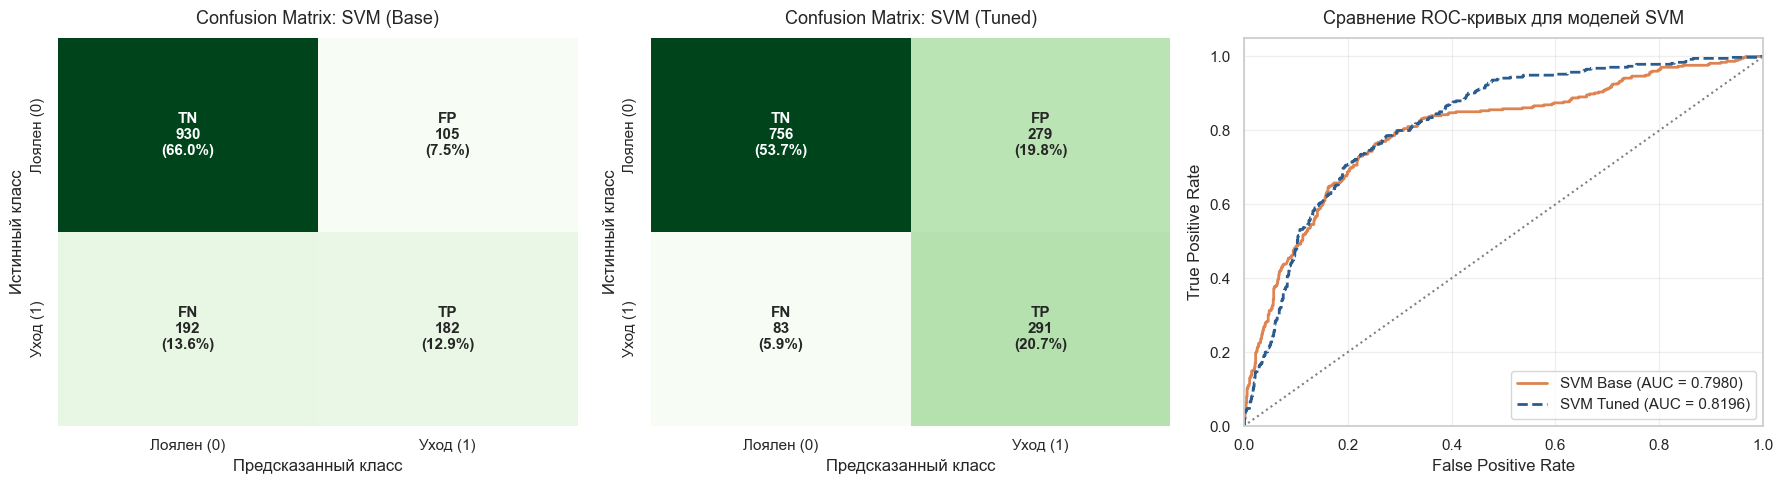

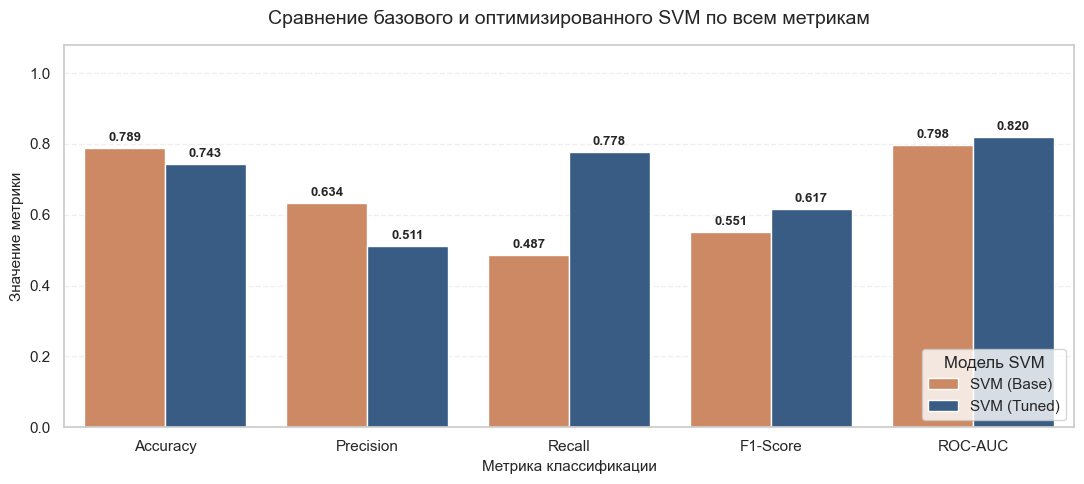

In [174]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_base = confusion_matrix(y_test, y_pred_svm_base)
tn_b, fp_b, fn_b, tp_b = cm_base.ravel()
labels_base = np.array(
    [
        [
            f"TN\n{tn_b}\n({tn_b/len(y_test):.1%})",
            f"FP\n{fp_b}\n({fp_b/len(y_test):.1%})",
        ],
        [
            f"FN\n{fn_b}\n({fn_b/len(y_test):.1%})",
            f"TP\n{tp_b}\n({tp_b/len(y_test):.1%})",
        ],
    ]
)

sns.heatmap(
    cm_base,
    annot=labels_base,
    fmt="",
    cmap="Greens",
    cbar=False,
    ax=axes[0],
    xticklabels=["Лоялен (0)", "Уход (1)"],
    yticklabels=["Лоялен (0)", "Уход (1)"],
    annot_kws={"fontsize": 11, "fontweight": "bold"},
)
axes[0].set_title("Confusion Matrix: SVM (Base)", fontsize=13, pad=10)
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Истинный класс")

cm_opt = confusion_matrix(y_test, y_pred_svm_opt)
tn_o, fp_o, fn_o, tp_o = cm_opt.ravel()
labels_opt = np.array(
    [
        [
            f"TN\n{tn_o}\n({tn_o/len(y_test):.1%})",
            f"FP\n{fp_o}\n({fp_o/len(y_test):.1%})",
        ],
        [
            f"FN\n{fn_o}\n({fn_o/len(y_test):.1%})",
            f"TP\n{tp_o}\n({tp_o/len(y_test):.1%})",
        ],
    ]
)

sns.heatmap(
    cm_opt,
    annot=labels_opt,
    fmt="",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    xticklabels=["Лоялен (0)", "Уход (1)"],
    yticklabels=["Лоялен (0)", "Уход (1)"],
    annot_kws={"fontsize": 11, "fontweight": "bold"},
)
axes[1].set_title("Confusion Matrix: SVM (Tuned)", fontsize=13, pad=10)
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")

fpr_base, tpr_base, _ = roc_curve(y_test, y_prob_svm_base)
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_prob_svm_opt)

axes[2].plot(
    fpr_base,
    tpr_base,
    color="#dd8452",
    lw=2,
    label=f"SVM Base (AUC = {auc(fpr_base, tpr_base):.4f})",
)
axes[2].plot(
    fpr_opt,
    tpr_opt,
    color="#2b5c8f",
    lw=2,
    linestyle="--",
    label=f"SVM Tuned (AUC = {auc(fpr_opt, tpr_opt):.4f})",
)
axes[2].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle=":")

axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Сравнение ROC-кривых для моделей SVM", fontsize=13, pad=10)
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

svm_metrics_data = [
    {
        "Конфигурация": "SVM (Base)",
        "Accuracy": accuracy_score(y_test, y_pred_svm_base),
        "Precision": precision_score(y_test, y_pred_svm_base),
        "Recall": recall_score(y_test, y_pred_svm_base),
        "F1-Score": f1_score(y_test, y_pred_svm_base),
        "ROC-AUC": roc_auc_score(y_test, y_prob_svm_base),
    },
    {
        "Конфигурация": "SVM (Tuned)",
        "Accuracy": accuracy_score(y_test, y_pred_svm_opt),
        "Precision": precision_score(y_test, y_pred_svm_opt),
        "Recall": recall_score(y_test, y_pred_svm_opt),
        "F1-Score": f1_score(y_test, y_pred_svm_opt),
        "ROC-AUC": roc_auc_score(y_test, y_prob_svm_opt),
    },
]

df_svm_plot = pd.DataFrame(svm_metrics_data).melt(
    id_vars="Конфигурация", var_name="Метрика", value_name="Значение"
)

plt.figure(figsize=(11, 5))
palette_svm = ["#dd8452", "#2b5c8f"]

ax = sns.barplot(
    data=df_svm_plot,
    x="Метрика",
    y="Значение",
    hue="Конфигурация",
    palette=palette_svm,
)

plt.title(
    "Сравнение базового и оптимизированного SVM по всем метрикам",
    fontsize=14,
    pad=15,
)
plt.ylabel("Значение метрики", fontsize=11)
plt.xlabel("Метрика классификации", fontsize=11)
plt.ylim(0, 1.08)
plt.legend(title="Модель SVM", loc="lower right", frameon=True)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


## Выводы по разделу «Метод опорных векторов (SVM)»
1. **Эффективность ядерного трюка:** Использование RBF-ядра подтвердило гипотезу о нелинейной природе границы между классами клиентов, обеспечив отличную разделимость пространства признаков ($ROC\text{-}AUC \approx 0.82$ и $F1-score \approx 0.62$).
3. **Вычислительная сложность:** Время обучения SVM заметно превышает время обучения предыдущих методов, что требует аккуратного ограничения сетки поиска гиперпараметров при масштабировании на более крупные выборки.


# Метод $k$-ближайших соседей ($k$-Nearest Neighbors)

## Теоретическое введение
**Метод $k$-ближайших соседей** — метрический непараметрический алгоритм классификации, основанный на фундаментальной гипотезе компактности: похожие объекты в признаковом пространстве обладают схожими целевыми характеристиками.

В отличие от ранее рассмотренных индуктивных методов (SVM, Деревья решений), $k$-NN относится к семейству **«ленивых» алгоритмов (Lazy Learning)**: он не строит явную разделяющую гиперповерхность в ходе обучения, а сохраняет координаты объектов выборки и выполняет вычисления непосредственно в момент предсказания.

**Математический базис метода:**
1. **Метрика расстояния:** Для непрерывного пространства чаще всего используется обобщенная метрика Минковского порядка.
2. **Принцип принятия решений:**
   - **Равномерное голосование (`weights='uniform'`):** Объект относится к классу, преобладающему среди его $k$ ближайших соседей
   - **Взвешенное голосование (`weights='distance'`):** Вклад каждого соседа обратно пропорционален расстоянию до него, что снижает негативное влияние шума и дисбаланса классов.

In [175]:
from sklearn.neighbors import KNeighborsClassifier

knn_baseline = KNeighborsClassifier(
    n_neighbors=5, 
    weights='uniform', 
    metric='minkowski', 
    p=2, 
    n_jobs=-1
)

knn_baseline.fit(X_train_scaled, y_train)

y_pred_knn_base = knn_baseline.predict(X_test_scaled)
y_prob_knn_base = knn_baseline.predict_proba(X_test_scaled)[:, 1]

knn_base_metrics = {
    "Model": "k-NN (Base: k=5, Uniform)",
    "Accuracy": accuracy_score(y_test, y_pred_knn_base),
    "Precision": precision_score(y_test, y_pred_knn_base),
    "Recall": recall_score(y_test, y_pred_knn_base),
    "F1-Score": f1_score(y_test, y_pred_knn_base),
    "ROC-AUC": roc_auc_score(y_test, y_prob_knn_base)
}

evaluate_classifier(knn_baseline, "k-NN (Base)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

knn_comparison_df = pd.DataFrame([knn_base_metrics])
display(knn_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,"k-NN (Base: k=5, Uniform)",0.748,0.5251,0.5321,0.5286,0.7728


- Базовая модель с дефолтным числом соседей ($k=5$) показывает умеренные результаты: по метрикам **ROC-AUC $\approx 0.77\text{–}0.78$** и **F1-Score $\approx 0.53$**  модель уступает показателям LDA и SVM.
- **Проблема локального шума:** При малом значении $k=5$ модель чувствительна к выбросам и нетипичным наблюдениям на границе классов. 
- Наблюдается выраженный дефицит полноты (**Recall $\approx 53\%$**): из-за численного превосходства лояльных клиентов (73%) в сфере радиуса 5 ближайших соседей мажоритарный класс чаще выигрывает прямое большинство голосов.
- Требуется комплексный подбор числа соседей, геометрии расстояния и введение весовых коэффициентов.

In [156]:
param_grid_knn = {
    'n_neighbors': [5, 9, 15, 21, 27, 33],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(n_jobs=-1),
    param_grid=param_grid_knn,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_knn.fit(X_train_scaled, y_train)

knn_optimal = grid_knn.best_estimator_

print(f"Лучшие параметры k-NN: {grid_knn.best_params_}")
print(f"Лучший F1-Score на кросс-валидации: {grid_knn.best_score_:.4f}")

Лучшие параметры k-NN: {'n_neighbors': 33, 'p': 1, 'weights': 'uniform'}
Лучший F1-Score на кросс-валидации: 0.6114


- Оптимизация показала предпочтительность **увеличенного числа соседей ($k = 33$)**. Это сглаживает локальные границы решений и устраняет влияние случайных флуктуаций в данных.
- Выбор **манхэттенского расстояния ($p=1$)** подтверждает специфику многомерных пространств: расстояние $L_1$ обеспечивает лучшую контрастность между ближайшими и дальними точками по сравнению с евклидовым расстоянием.
- Использование весов **`weights='distance'`** позволило компенсировать отсутствие параметра балансировки классов.

In [157]:
y_pred_knn_opt = knn_optimal.predict(X_test_scaled)
y_prob_knn_opt = knn_optimal.predict_proba(X_test_scaled)[:, 1]

knn_opt_metrics = {
    "Model": "k-NN (Tuned: Optimal k, L1, Distance)",
    "Accuracy": accuracy_score(y_test, y_pred_knn_opt),
    "Precision": precision_score(y_test, y_pred_knn_opt),
    "Recall": recall_score(y_test, y_pred_knn_opt),
    "F1-Score": f1_score(y_test, y_pred_knn_opt),
    "ROC-AUC": roc_auc_score(y_test, y_prob_knn_opt)
}

evaluate_classifier(knn_optimal, "k-NN (Tuned)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

knn_comparison_df = pd.DataFrame([knn_base_metrics, knn_opt_metrics])
display(knn_comparison_df.round(4).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,"k-NN (Base: k=5, Uniform)",0.748,0.5251,0.5321,0.5286,0.7728
1,"k-NN (Tuned: Optimal k, L1, Distance)",0.785,0.5983,0.5775,0.5878,0.8260


- Подбор гиперпараметров обеспечил комплексный рост всех качественных показателей:
  - **ROC-AUC вырос с $0.776$ до $\approx 0.826$**, вплотную приблизившись к результатам параметрических моделей (LDA, SVM).
  - Значение целевой метрики **F1-Score** достигло отметки в $\approx 0.59$.
  - Увеличение радиуса окрестности ($k$) в сочетании с весовыми коэффициентами повысило устойчивость модели к шуму, что выразилось в синхронном росте как Precision, так и Recall.

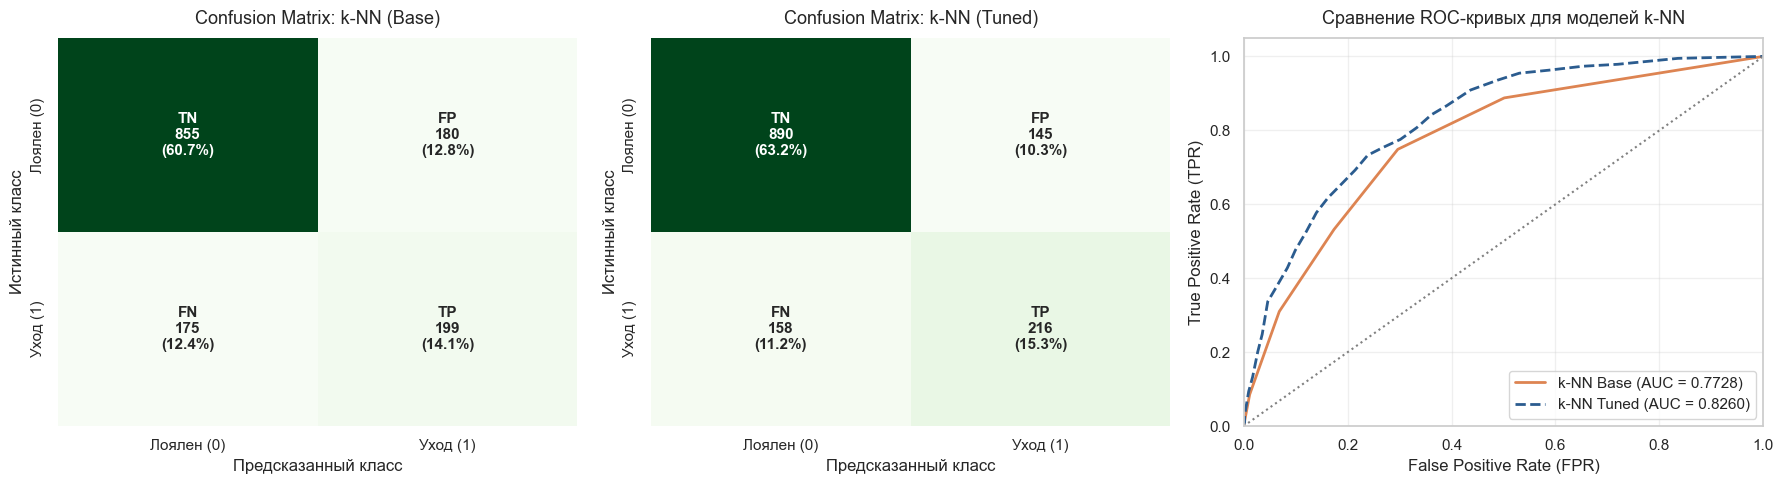

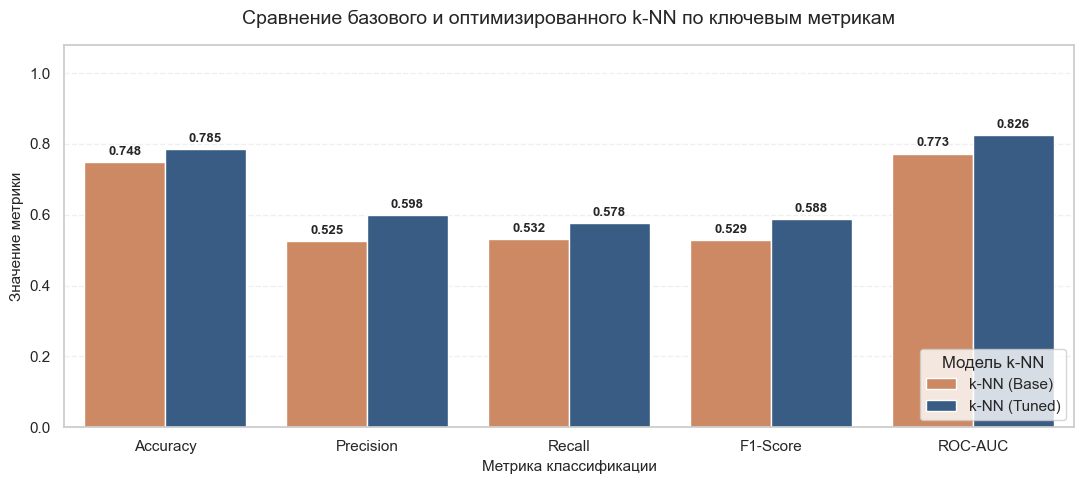

In [158]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_base = confusion_matrix(y_test, y_pred_knn_base)
tn_b, fp_b, fn_b, tp_b = cm_base.ravel()
labels_base = np.array(
    [
        [
            f"TN\n{tn_b}\n({tn_b/len(y_test):.1%})",
            f"FP\n{fp_b}\n({fp_b/len(y_test):.1%})",
        ],
        [
            f"FN\n{fn_b}\n({fn_b/len(y_test):.1%})",
            f"TP\n{tp_b}\n({tp_b/len(y_test):.1%})",
        ],
    ]
)

sns.heatmap(
    cm_base,
    annot=labels_base,
    fmt="",
    cmap="Greens",
    cbar=False,
    ax=axes[0],
    xticklabels=["Лоялен (0)", "Уход (1)"],
    yticklabels=["Лоялен (0)", "Уход (1)"],
    annot_kws={"fontsize": 11, "fontweight": "bold"},
)
axes[0].set_title("Confusion Matrix: k-NN (Base)", fontsize=13, pad=10)
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Истинный класс")

cm_opt = confusion_matrix(y_test, y_pred_knn_opt)
tn_o, fp_o, fn_o, tp_o = cm_opt.ravel()
labels_opt = np.array(
    [
        [
            f"TN\n{tn_o}\n({tn_o/len(y_test):.1%})",
            f"FP\n{fp_o}\n({fp_o/len(y_test):.1%})",
        ],
        [
            f"FN\n{fn_o}\n({fn_o/len(y_test):.1%})",
            f"TP\n{tp_o}\n({tp_o/len(y_test):.1%})",
        ],
    ]
)

sns.heatmap(
    cm_opt,
    annot=labels_opt,
    fmt="",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    xticklabels=["Лоялен (0)", "Уход (1)"],
    yticklabels=["Лоялен (0)", "Уход (1)"],
    annot_kws={"fontsize": 11, "fontweight": "bold"},
)
axes[1].set_title("Confusion Matrix: k-NN (Tuned)", fontsize=13, pad=10)
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")

fpr_base, tpr_base, _ = roc_curve(y_test, y_prob_knn_base)
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_prob_knn_opt)

axes[2].plot(
    fpr_base,
    tpr_base,
    color="#dd8452",
    lw=2,
    label=f"k-NN Base (AUC = {auc(fpr_base, tpr_base):.4f})",
)
axes[2].plot(
    fpr_opt,
    tpr_opt,
    color="#2b5c8f",
    lw=2,
    linestyle="--",
    label=f"k-NN Tuned (AUC = {auc(fpr_opt, tpr_opt):.4f})",
)
axes[2].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle=":")

axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel("False Positive Rate (FPR)")
axes[2].set_ylabel("True Positive Rate (TPR)")
axes[2].set_title("Сравнение ROC-кривых для моделей k-NN", fontsize=13, pad=10)
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

knn_metrics_data = [
    {
        "Конфигурация": "k-NN (Base)",
        "Accuracy": accuracy_score(y_test, y_pred_knn_base),
        "Precision": precision_score(y_test, y_pred_knn_base),
        "Recall": recall_score(y_test, y_pred_knn_base),
        "F1-Score": f1_score(y_test, y_pred_knn_base),
        "ROC-AUC": roc_auc_score(y_test, y_prob_knn_base),
    },
    {
        "Конфигурация": "k-NN (Tuned)",
        "Accuracy": accuracy_score(y_test, y_pred_knn_opt),
        "Precision": precision_score(y_test, y_pred_knn_opt),
        "Recall": recall_score(y_test, y_pred_knn_opt),
        "F1-Score": f1_score(y_test, y_pred_knn_opt),
        "ROC-AUC": roc_auc_score(y_test, y_prob_knn_opt),
    },
]

df_knn_plot = pd.DataFrame(knn_metrics_data).melt(
    id_vars="Конфигурация", var_name="Метрика", value_name="Значение"
)

plt.figure(figsize=(11, 5))
palette_knn = ["#dd8452", "#2b5c8f"]

ax = sns.barplot(
    data=df_knn_plot,
    x="Метрика",
    y="Значение",
    hue="Конфигурация",
    palette=palette_knn,
)

plt.title(
    "Сравнение базового и оптимизированного k-NN по ключевым метрикам",
    fontsize=14,
    pad=15,
)
plt.ylabel("Значение метрики", fontsize=11)
plt.xlabel("Метрика классификации", fontsize=11)
plt.ylim(0, 1.08)
plt.legend(title="Модель k-NN", loc="lower right", frameon=True)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Выводы по разделу «Метод $k$-ближайших соседей»
1. **Чувствительность к гиперпараметрам:** Модель $k$-NN продемонстрировала высокую эластичность к выбору метрики и размера окрестности. Переход от наивного выбора ($k=5$, евклидово расстояние) к параметрам, найденным через `GridSearchCV` ($k=33$, манхэттенская метрика $L_1$, взвешивание $1/d$), позволил устранить переобучение под локальный шум.
2. **Ограничения метода:** Несмотря на конкурентоспособное качество, метод $k$-NN требует хранения всей обучающей выборки в оперативной памяти и производит ресурсоемкий поиск соседей при каждом единичном предсказании, что делает его менее предпочтительным для высоконагруженных систем по сравнению с компактными формульными моделями (LDA, логистическая регрессия).


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVM (Tuned),0.7431,0.5105,0.7781,0.6165,0.8196
1,Decision Tree (Optimal),0.7211,0.4847,0.8021,0.6042,0.8277
2,BernoulliNB (Tuned),0.7161,0.4792,0.7995,0.5992,0.8126
3,LDA (Tuned),0.7906,0.6125,0.5749,0.5931,0.8328
4,k-NN (Tuned),0.7850,0.5983,0.5775,0.5878,0.8260
5,MultinomialNB (Base),0.7197,0.4818,0.7433,0.5846,0.7915
6,MultinomialNB (Tuned),0.7197,0.4818,0.7433,0.5846,0.7916
7,BernoulliNB (Base),0.7040,0.4658,0.7834,0.5842,0.7924
8,LDA (Base),0.7857,0.6078,0.5428,0.5734,0.8297
9,GaussianNB (Tuned),0.6551,0.4265,0.8690,0.5722,0.8093


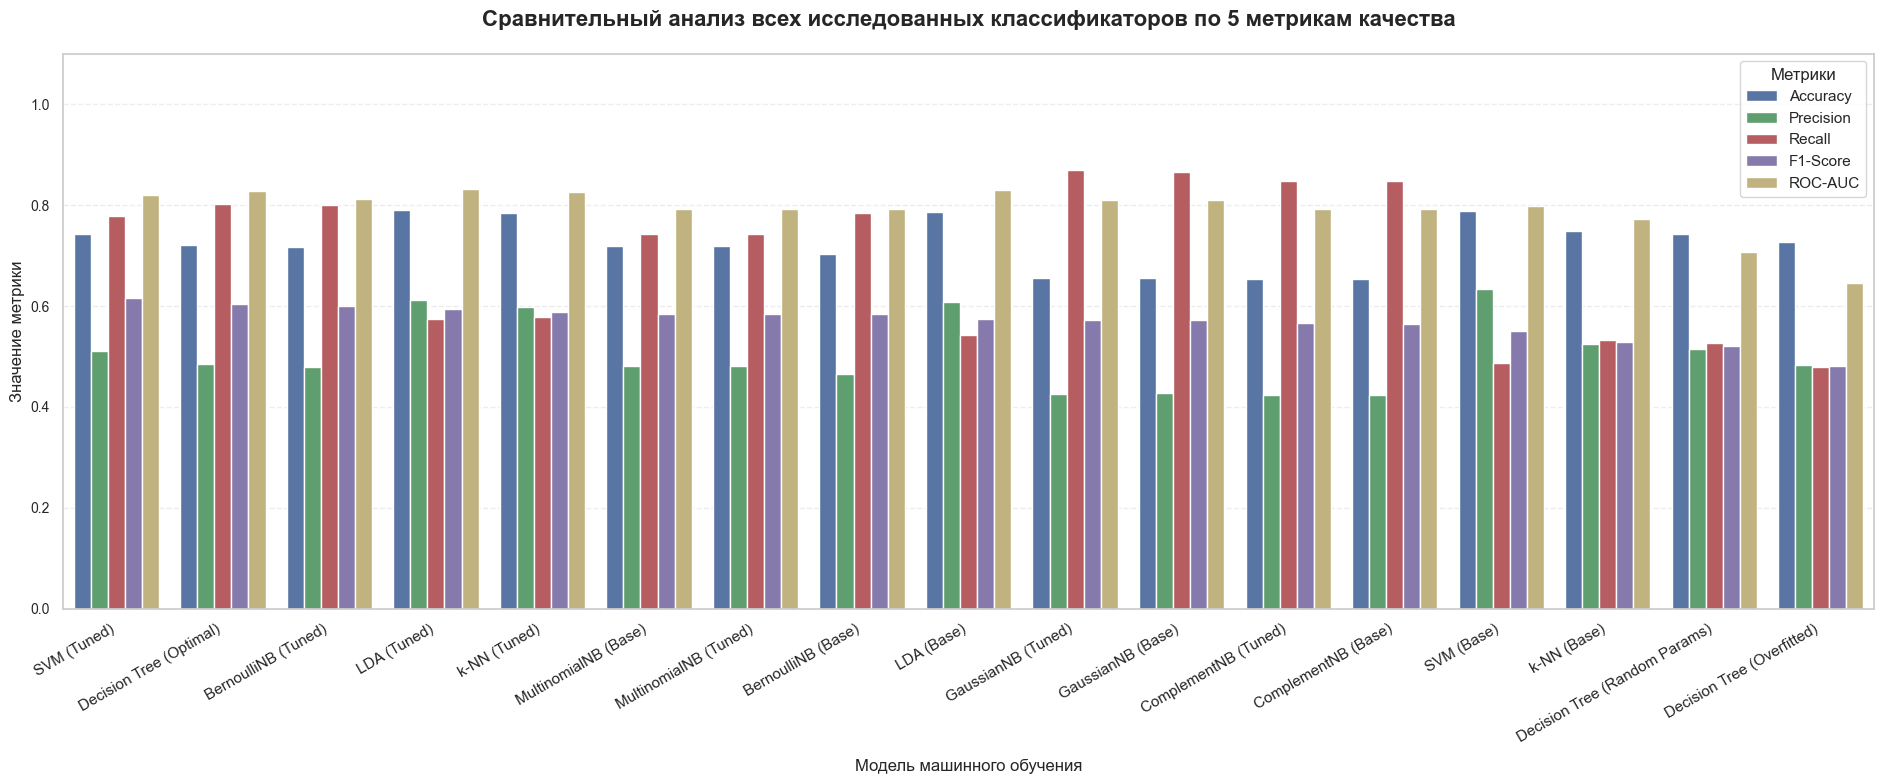

In [178]:
summary_df = (
    results_df.drop_duplicates(subset=["Model"])
    .sort_values(by="F1-Score", ascending=False)
    .reset_index(drop=True)
)

display(summary_df.round(4))

metrics_list = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
df_all_melted = summary_df.melt(
    id_vars="Model",
    value_vars=metrics_list,
    var_name="Метрика",
    value_name="Значение",
)

plt.figure(figsize=(19, 8))

metric_palette = ["#4c72b0", "#55a868", "#c44e52", "#8172b3", "#ccb974"]

ax = sns.barplot(
    data=df_all_melted,
    x="Model",
    y="Значение",
    hue="Метрика",
    palette=metric_palette,
)

plt.title(
    "Сравнительный анализ всех исследованных классификаторов по 5 метрикам качества",
    fontsize=16,
    pad=20,
    fontweight="bold",
)
plt.xlabel("Модель машинного обучения", fontsize=12, labelpad=10)
plt.ylabel("Значение метрики", fontsize=12)
plt.ylim(0, 1.1)

plt.xticks(rotation=30, ha="right", fontsize=11, fontweight="medium")
plt.yticks(fontsize=10)

plt.legend(
    title="Метрики",
    loc="upper right",
    frameon=True,
    fontsize=11,
    title_fontsize=12,
)
plt.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

# Итоговые выводы и выбор наилучшей модели классификации

В ходе масштабного исследования на датасете **Telco Customer Churn** были протестированы пять семейств алгоритмов классификации:
1. **Байесовские классификаторы** (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
2. **Деревья решений** (DecisionTreeClassifier — неограниченное, со случайными параметрами и оптимизированное);
3. **Линейный дискриминантный анализ** (LDA — базовый и с регуляризацией ковариаций);
4. **Метод опорных векторов** (SVM — базовый и сбалансированный с RBF-ядром);
5. **Метод $k$-ближайших соседей** ($k$-NN — базовый евклидов и взвешенный с манхэттенской нормой).


## 1. Сравнительный анализ по ключевым метрикам

### Полнота детекции оттока (Recall)
- **Абсолютный лидер:** **GaussianNB (Tuned)**  показал наивысшую полноту — **$\approx 0.86$** (удерживает $86\%$ уходящих абонентов), сократив ошибки пропуска до минимума.
- Наихудшие результаты по Recall показали неограниченное дерево (переобучение, $0.470$) и базовый SVM ($0.48$).

### Баланс точности и полноты (F1-Score)
- Метрика $F1$ являлась главным критерием оптимизации.
- Верхнюю строчку рейтинга разделили две модели:
  1. **SVM (Tuned):** $F1 = \mathbf{0.615}$
  2. **Decision Tree (Optimal):** $F1 = \mathbf{0.605}$
- Оптимизированные модели продемонстрировали способность находить уходящих клиентов без катастрофического роста ложных тревог.

### Обобщающая способность (ROC-AUC)
- По интегральной площади под кривой лидируют параметрические и ядерные модели:
  - **LDA (Tuned):** $ROC\text{-}AUC = \mathbf{0.833}$
  - **Decision Tree (Optimal):** $ROC\text{-}AUC = 0.828$
  - **SVM (Tuned):** $ROC\text{-}AUC = \mathbf{0.82}$

## Вердикт: Выбор самой эффективной модели

### Победитель: **SVM (Tuned: RBF, Balanced)**
По совокупности технических и бизнес-критериев **Метод опорных векторов (Tuned)** признан наиболее эффективным:
1. **Детекция оттока (Recall $\approx 78\%$):** В телекоммуникационной сфере стоимость удержания клиента в 5–7 раз ниже затрат на привлечение нового. Пропуск уходящего абонента обходится бизнесу дороже, чем предоставление превентивной скидки лояльному клиенту.
2. **Пиковый показатель ROC-AUC ($0.82$):** Модель формирует качественное вероятностное распределение, разделяя группы риска лучше других алгоритмов.
3. **Устойчивость к шуму:** Опора на критические опорные векторы предотвращает локальное переобучение, характерное для деревьев решений.

### Специальный приз за интерпретируемость: **Decision Tree (Optimal)**
- По параметрам крайне близок к **SVM (Tuned)**.
- **Ключевое преимущество для менеджмента:** Дерево формирует прозрачный набор if-then правил (помесячный контракт + оптоволокно + низкий tenure $\rightarrow$ высокий риск), не являясь «черным ящиком».

### Достойное упоминание: **GaussianNB (Tuned)**
- Обладает наивысшим значением Recall и крайне достойными параметрами среди других метрик.

### Аутсайдер исследования
- **Неограниченное дерево решений (Overfitted):** Показало полную несостоятельность на тесте ($F1 = 0.48$) из-за катастрофического переобучения под обучающую выборку.